# Large-Scale Persian (Farsi) Grapheme-to-Phoneme (G2P) Fine-Tuning & Comprehensive Benchmark Suite
### Built on [CharsiuG2P (Interspeech 2022)](https://github.com/lingjzhu/CharsiuG2P) & Byte-Level Transformer Seq2Seq (`ByT5`)

---

### Executive Summary & Architectural Scope
**Grapheme-to-Phoneme (G2P)** conversion maps orthographic text sequences into International Phonetic Alphabet (IPA) representations. For the **Persian (Farsi)** language (`<fas>`), neural G2P modeling faces four core linguistic challenges:
1. **Unvocalized Short Vowels (Diacritic Omission)**: Standard Persian script omits short vowels (`/æ/` Fathe, `/e/` Kasre, `/o/` Zamme), causing severe homographic and phonotactic ambiguity.
2. **Compound Words & Ezafe Morphophonemics**: Unwritten enclitic vowels (`-e` after consonants, `-je` after vowels) link noun-modifier constructions.
3. **Gemination (Tashdid) & Glottal Stops (Hamza / Ayn)**: Arabic-derived morphological templates (`تَفَعُّل`, `مُفَعَّل`, `اِفتِعال`) feature doubled consonants and glottal stops (`/ʔ/`) that generic multilingual models frequently drop.
4. **Modern AI, Computing & Technical Loanwords**: Rapidly evolving technical terminology (*Algorithm, PyTorch, TensorFlow, Transformer, Kaggle, Keras, Tokenizer, Convolution*) requires specialized phonetic adaptation.

### Key Highlights of This Upgraded Notebook
* **Large-Scale Training Corpus ($N = 8,559$ instances)**: Combines the complete official Wiktionary Persian training split (`7,149` entries from `CharsiuG2P/data/train/fas.tsv`) with a curated `235`-entry Persian Linguistic & Technical Lexicon (oversampled $6\times$ for balanced domain adaptation).
* **Dual Evaluation Benchmarks ($N = 560$ test words)**:
  1. **Official Wiktionary Unseen Test Split ($N = 500$ words)**: Evaluates broad lexical generalization on unseen Persian words.
  2. **Held-Out Stratified Challenge Suite ($N = 60$ words across 4 categories, none seen during training)**: Evaluates precision on *AI & Tech Loanwords*, *Short-Vowel Ambiguity*, *Compound & Ezafe Constructions*, and *Gemination & Glottal Stops*.
* **9 Phonetic & Sequence Evaluation Metrics**:
  * Phoneme Error Rate (**PER %**), Word Error Rate (**WER %**), Exact Word Accuracy (**WAcc %**), Normalized Edit Similarity (**Sim %**), Phonetic Character N-Gram F1 (**chrF %**), and Levenshtein Edit Operation Decomposition (**Substitution %**, **Deletion %**, **Insertion %**), plus **Vowel Confusion Matrices** and **Length-Stratified Error Analysis**.
* **9 High-Resolution (300 DPI) Visualizations**: Exported automatically to `./figures/` for publication and technical reporting.


In [1]:
# Step 1: Hardware Acceleration & Environment Setup
import os
import re
import sys
import time
import json
import math
import inspect
from collections import Counter
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print(f"Python Version  : {sys.version.split()[0]}")
print(f"PyTorch Version : {torch.__version__}")
gpu_available = torch.cuda.is_available()
print(f"GPU Available   : {gpu_available}")

if gpu_available:
    device = torch.device("cuda")
    print(f"Active GPU      : {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM      : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    device = torch.device("cpu")
    print("WARNING: GPU not detected. Running on CPU fallback.")

!pip install -q accelerate evaluate jiwer tabulate matplotlib seaborn
import seaborn as sns
from tabulate import tabulate
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    T5ForConditionalGeneration,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    TrainerCallback
)

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)
print("Environment and directories initialized successfully.")


Python Version  : 3.13.15
PyTorch Version : 2.11.0+cu128
GPU Available   : True
Active GPU      : Tesla T4
Total VRAM      : 14.56 GB
Environment and directories initialized successfully.


## Section 1: Cloning CharsiuG2P & Constructing the Large-Scale Persian Corpus
We clone the official [CharsiuG2P repository](https://github.com/lingjzhu/CharsiuG2P) to access the raw Persian Wiktionary lexicon (`data/train/fas.tsv`, `data/dev/fas.tsv`, `data/test/fas.tsv`) and augment it with our curated Persian Linguistic & Domain Lexicon. A separate 60-word challenge set is held out from training and validation, and an explicit leakage audit verifies that no challenge word appears in the training data.


In [2]:
# Clone CharsiuG2P repository if not present
if not os.path.exists("CharsiuG2P"):
    !git clone --depth 1 https://github.com/lingjzhu/CharsiuG2P.git
    print("CharsiuG2P repository cloned successfully.")
else:
    print("CharsiuG2P repository already present.")

# 1. Domain seed lexicon (60 words, 4 categories) -- used for TRAINING only
DOMAIN_SEED_SET = {
    'AI & Tech Loanwords': [
        ('الگوریتم', 'ʔælɡoɾiːtm'),
        ('پایتورچ', 'pɒːjtɔːɾt͡ʃ'),
        ('تنسورفلو', 'tensoɾfloʊ'),
        ('ترنسفورمر', 'tɾænsfoɾmeɾ'),
        ('کگل', 'kæɡel'),
        ('کراس', 'keɾɒːs'),
        ('چت\u200cجی\u200cپی\u200cتی', 't͡ʃætd͡ʒiːpiːtiː'),
        ('دیپ\u200cلرنینگ', 'diːpleɾniːŋɡ'),
        ('توکنایزر', 'tokenɒːjzeɾ'),
        ('کانولوشن', 'kɒːnvoluːʃæn'),
        ('گرادیان', 'ɡeɾɒːdjɒːn'),
        ('دیتاست', 'dejtɒːset'),
        ('فریم\u200cورک', 'fɾejmvoɾk'),
        ('کوبرنتیز', 'kuːbeɾnetiːz'),
        ('پایتون', 'pɒːjton'),
    ],
    'Short-Vowel Ambiguity': [
        ('شبکه', 'ʃæbæke'),
        ('مدل', 'model'),
        ('پردازش', 'pæɾdɒːzeʃ'),
        ('مهندسی', 'mohændesiː'),
        ('پزشکی', 'pezeʃkiː'),
        ('محاسبه', 'mohɒːsebe'),
        ('معادله', 'moʔɒːdele'),
        ('احتمال', 'ehtemɒːl'),
        ('پژوهش', 'pæʒuːheʃ'),
        ('نرم\u200cافزار', 'næɾmæfzɒːɾ'),
        ('سخت\u200cافزار', 'sæxtæfzɒːɾ'),
        ('گرافیم', 'ɡeɾɒːfem'),
        ('نویسه', 'neviːse'),
        ('بهینه\u200cسازی', 'behiːnesɒːziː'),
        ('بهره\u200cوری', 'bæhɾevæɾiː'),
    ],
    'Compound & Ezafe': [
        ('هوش مصنوعی', 'huːʃemæsnuːʔiː'),
        ('یادگیری ماشین', 'jɒːdɡiːɾiːjemɒːʃiːn'),
        ('یادگیری عمیق', 'jɒːdɡiːɾiːjeʔæmiːɢ'),
        ('شبکه عصبی', 'ʃæbækejeʔæsæbiː'),
        ('زبان طبیعی', 'zæbɒːnetæbiːʔiː'),
        ('دانشگاه تهران', 'dɒːneʃɡɒːhetæhɾɒːn'),
        ('مدل زبانی', 'modelezæbɒːniː'),
        ('پردازش گفتار', 'pæɾdɒːzeʃeɡoftɒːɾ'),
        ('تولید گفتار', 'toʊliːdeɡoftɒːɾ'),
        ('بینایی ماشین', 'biːnɒːjiːjemɒːʃiːn'),
        ('پایگاه داده', 'pɒːjɡɒːhedɒːde'),
        ('فضای برداری', 'fæzɒːjebæɾdɒːɾiː'),
        ('خطای واجی', 'xætɒːjevɒːd͡ʒiː'),
        ('بازنمایی آوایی', 'bɒːznæmɒːjiːjeɒːvɒːjiː'),
        ('علم داده', 'elmedɒːde'),
    ],
    'Gemination & Glottal': [
        ('مصنوعی', 'mæsnuːʔiː'),
        ('طبیعی', 'tæbiːʔiː'),
        ('مسئله', 'mæsʔæle'),
        ('مسئولیت', 'mæsʔuːliːjæt'),
        ('تأثیر', 'tæʔsiːɾ'),
        ('تأیید', 'tæʔjiːd'),
        ('مؤثر', 'moʔæsseɾ'),
        ('معرفی', 'moʔæɾɾefiː'),
        ('متغیر', 'motæɢæjjeɾ'),
        ('مربع', 'moɾæbbæʔ'),
        ('مکعب', 'mokæʔʔæb'),
        ('توجه', 'tævæd͡ʒd͡ʒoh'),
        ('تفکر', 'tæfækkoɾ'),
        ('اتصال', 'ettesɒːl'),
        ('اطلاعات', 'ettelɒːʔɒːt'),
    ],
}

# 2. Additional curated lexicon (200 entries); entries [:25] are reserved for validation
ADDITIONAL_CURATED_LEXICON = [
    ('بک\u200cپراپگیشن', 'bækpɾɒːpæɡejʃæn'),
    ('انکودر', 'enkodeɾ'),
    ('دیکودر', 'diːkodeɾ'),
    ('امبدینگ', 'embediːŋɡ'),
    ('فاین\u200cتیونینگ', 'fɒːjntjuːniːŋɡ'),
    ('ریگرسیون', 'ɾeɡɾesjon'),
    ('کلاسیفیکیشن', 'klæsiːfiːkejʃæn'),
    ('سگمنتیشن', 'seɡmentejʃæn'),
    ('هایپرپارامتر', 'hɒːjpeɾpɒːɾɒːmetɾ'),
    ('لرنینگ\u200cریت', 'leɾniːŋɡɾejt'),
    ('اورفیتینگ', 'oʊveɾfiːtiːŋɡ'),
    ('آندرفیتینگ', 'ɒːndeɾfiːtiːŋɡ'),
    ('ترنسفرلرنینگ', 'tɾænsfeɾleɾniːŋɡ'),
    ('چک\u200cپوینت', 't͡ʃekpojnt'),
    ('هاگینگ\u200cفیس', 'hɒːɡiːŋɡfejs'),
    ('آرکایو', 'ɒːɾkɒːjv'),
    ('کودا', 'kuːdɒː'),
    ('وکتور', 'vektoɾ'),
    ('ماتریس', 'mɒːtɾiːs'),
    ('تنسور', 'tensoɾ'),
    ('داکر', 'dɒːkeɾ'),
    ('گیت\u200cهاب', 'ɡiːthɒːb'),
    ('لینوکس', 'liːnuːks'),
    ('جاوااسکریپت', 'd͡ʒɒːvɒːeskɾiːpt'),
    ('تایپ\u200cاسکریپت', 'tɒːjpeskɾiːpt'),
    ('فست\u200cای\u200cپی\u200cآی', 'fæstejpiːɒːj'),
    ('جوپیتر', 'd͡ʒuːpiːteɾ'),
    ('لنگ\u200cچین', 'læŋɡt͡ʃejn'),
    ('لاما', 'lɒːmɒː'),
    ('میسترال', 'miːstɾɒːl'),
    ('پستگرس', 'postɡɾes'),
    ('رزنت', 'ɾeznet'),
    ('نرف', 'neɾf'),
    ('ویسپر', 'viːspeɾ'),
    ('کلود', 'klɒːʊd'),
    ('سرور', 'seɾveɾ'),
    ('پایپ\u200cلاین', 'pɒːjplɒːjn'),
    ('فرانت\u200cاند', 'fɾɒːntend'),
    ('بک\u200cاند', 'bækend'),
    ('فول\u200cاستک', 'fuːlestæk'),
    ('دیواپس', 'devɒːps'),
    ('میکروسرویس', 'miːkɾoseɾviːs'),
    ('ای\u200cپی\u200cآی', 'ejpiːɒːj'),
    ('دیباگ', 'diːbɒːɡ'),
    ('کامپایلر', 'kɒːmpɒːjleɾ'),
    ('مفسر', 'mofæsseɾ'),
    ('باینری', 'bɒːjnæɾiː'),
    ('ماژول', 'mɒːʒuːl'),
    ('پکیج', 'pækejd͡ʒ'),
    ('ریپازیتوری', 'ɾiːpɒːziːtoɾiː'),
    ('کامیت', 'kɒːmiːt'),
    ('برنچ', 'bɾænt͡ʃ'),
    ('پول\u200cریکوئست', 'puːlɾiːkuːʔest'),
    ('کانتینر', 'kɒːntejneɾ'),
    ('مجازی\u200cسازی', 'mæd͡ʒɒːziːsɒːziː'),
    ('پروتکل', 'pɾotokol'),
    ('سوکت', 'soket'),
    ('الگوریتم\u200cهای', 'ʔælɡoɾiːtmhɒːj'),
    ('مدل\u200cهای', 'modelhɒːj'),
    ('ترنسفورمرها', 'tɾænsfoɾmeɾhɒː'),
    ('الگو', 'olɡuː'),
    ('ساختار', 'sɒːxtɒːɾ'),
    ('معماری', 'meʔmɒːɾiː'),
    ('پردازنده', 'pæɾdɒːzænde'),
    ('حافظه', 'hɒːfeze'),
    ('ذخیره\u200cسازی', 'zæxiːɾesɒːziː'),
    ('فشرده\u200cسازی', 'feʃoɾdesɒːziː'),
    ('رمزنگاری', 'ɾæmzneɡɒːɾiː'),
    ('امنیت', 'æmniːjæt'),
    ('مدیریت', 'modiːɾiːjæt'),
    ('پیکربندی', 'pejkæɾbændiː'),
    ('مقیاس\u200cپذیری', 'meɢjɒːspæziːɾiː'),
    ('پایداری', 'pɒːjdɒːɾiː'),
    ('کارایی', 'kɒːɾɒːjiː'),
    ('بازدهی', 'bɒːzdehiː'),
    ('پیچیدگی', 'piːt͡ʃiːdeɡiː'),
    ('همگرایی', 'hæmɡeɾɒːjiː'),
    ('واگرایی', 'vɒːɡeɾɒːjiː'),
    ('مشتق', 'moʃtæɢ'),
    ('انتگرال', 'enteɡɾɒːl'),
    ('واریانس', 'vɒːɾjɒːns'),
    ('انحراف', 'enheɾɒːf'),
    ('معیار', 'meʔjɒːɾ'),
    ('توزیع', 'toʊziːʔ'),
    ('نمونه\u200cبرداری', 'nemuːnebæɾdɒːɾiː'),
    ('برآورد', 'bæɾɒːvoɾd'),
    ('آزمون', 'ɒːzmuːn'),
    ('فرضیه', 'fæɾziːje'),
    ('همبستگی', 'hæmbæsteɡiː'),
    ('علیت', 'elliːjæt'),
    ('استنتاج', 'estentɒːd͡ʒ'),
    ('استدلال', 'estedlɒːl'),
    ('منطق', 'mænteɢ'),
    ('فلسفه', 'fælsæfe'),
    ('زبان\u200cشناسی', 'zæbɒːnʃenɒːsiː'),
    ('واج\u200cشناسی', 'vɒːd͡ʒʃenɒːsiː'),
    ('آواشناسی', 'ɒːvɒːʃenɒːsiː'),
    ('تکواژ', 'tækvɒːʒ'),
    ('صرف', 'sæɾf'),
    ('نحو', 'næhv'),
    ('معناشناسی', 'mæʔnɒːʃenɒːsiː'),
    ('کاربردشناسی', 'kɒːɾboɾdʃenɒːsiː'),
    ('گفتمان', 'ɡoftemɒːn'),
    ('بافتار', 'bɒːftɒːɾ'),
    ('ساختواژه', 'sɒːxtvɒːʒe'),
    ('هم\u200cآوا', 'hæmɒːvɒː'),
    ('هم\u200cنگاره', 'hæmneɡɒːɾe'),
    ('چندمعنایی', 't͡ʃændmæʔnɒːjiː'),
    ('ابهام\u200cزدایی', 'ebhɒːmzedɒːjiː'),
    ('برچسب\u200cگذاری', 'bæɾt͡ʃæsbɡozɒːɾiː'),
    ('شبکه\u200cهای عصبی', 'ʃæbækehɒːjeʔæsæbiː'),
    ('پردازش زبان', 'pæɾdɒːzeʃezæbɒːn'),
    ('تبدیل متن', 'tæbdiːlemætn'),
    ('تشخیص گفتار', 'tæʃxiːseɡoftɒːɾ'),
    ('یادگیری تقویتی', 'jɒːdɡiːɾiːjetæɢviːjætiː'),
    ('یادگیری نظارت\u200cشده', 'jɒːdɡiːɾiːjenezɒːɾætʃode'),
    ('یادگیری خودنظارتی', 'jɒːdɡiːɾiːjexodnezɒːɾætiː'),
    ('مدل پایه', 'modelepɒːje'),
    ('مدل مولد', 'modelemovælled'),
    ('شبکه مولد', 'ʃæbækejemovælled'),
    ('توزیع احتمال', 'toʊziːʔeehtemɒːl'),
    ('تابع هزینه', 'tɒːbeʔehæziːne'),
    ('تابع زیان', 'tɒːbeʔeziːjɒːn'),
    ('کاهش گرادیان', 'kɒːheʃeɡeɾɒːdjɒːn'),
    ('شتاب\u200cدهنده گرافیکی', 'ʃetɒːbdehændejeɡeɾɒːfiːkiː'),
    ('پردازش موازی', 'pæɾdɒːzeʃemovɒːziː'),
    ('محاسبات ابری', 'mohɒːsebɒːteæbɾiː'),
    ('سیستم عامل', 'siːstemeɒːmel'),
    ('مهندسی نرم\u200cافزار', 'mohændesiːjenæɾmæfzɒːɾ'),
    ('معماری کامپیوتر', 'meʔmɒːɾiːjekɒːmpjuːteɾ'),
    ('ساختمان داده', 'sɒːxtemɒːnedɒːde'),
    ('طراحی الگوریتم', 'tæɾɾɒːhiːjeʔælɡoɾiːtm'),
    ('هوش محاسباتی', 'huːʃemohɒːsebɒːtiː'),
    ('منطق فازی', 'mænteɢefɒːziː'),
    ('الگوریتم ژنتیک', 'ʔælɡoɾiːtmeʒenetiːk'),
    ('درخت تصمیم', 'deɾæxtetæsmiːm'),
    ('جنگل تصادفی', 'd͡ʒænɡæletæsɒːdofiː'),
    ('ماشین بردار', 'mɒːʃiːnebæɾdɒːɾ'),
    ('خوشه\u200cبندی داده', 'xuːʃebændiːjedɒːde'),
    ('کاهش ابعاد', 'kɒːheʃeæbʔɒːd'),
    ('تحلیل مؤلفه', 'tæhliːlemoʔællefe'),
    ('سری زمانی', 'seɾiːjezæmɒːniː'),
    ('پیش\u200cبینی روند', 'piːʃbiːniːjeɾævænd'),
    ('ارزیابی عملکرد', 'ʔæɾzjɒːbiːjeæmælkæɾd'),
    ('خطای میانگین', 'xætɒːjemiːjɒːnɡiːn'),
    ('تخصص', 'tæxæssos'),
    ('متخصص', 'motæxæsses'),
    ('تحقق', 'tæhæɢɢoɢ'),
    ('محقق', 'mohæɢɢeɢ'),
    ('تمدن', 'tæmæddon'),
    ('تولیدکننده', 'toʊliːdkonænde'),
    ('مصرف\u200cکننده', 'mæsɾæfkonænde'),
    ('تعیین', 'tæʔjiːn'),
    ('معین', 'moʔæjjæn'),
    ('تغییر', 'tæɢjiːɾ'),
    ('تغییرات', 'tæɢjiːɾɒːt'),
    ('تأخیر', 'tæʔxiːɾ'),
    ('تأمین', 'tæʔmiːn'),
    ('تأسیس', 'tæʔsiːs'),
    ('تألیف', 'tæʔliːf'),
    ('مؤلف', 'moʔællef'),
    ('مؤلفه', 'moʔællefe'),
    ('مؤسسه', 'moʔæssese'),
    ('رئیس', 'ɾæʔiːs'),
    ('رؤیا', 'ɾoʔjɒː'),
    ('سؤال', 'soʔɒːl'),
    ('مسئول', 'mæsʔuːl'),
    ('جرئت', 'd͡ʒoɾʔæt'),
    ('هیئت', 'hejʔæt'),
    ('تشکر', 'tæʃækkoɾ'),
    ('تحول', 'tæhævvol'),
    ('تقدم', 'tæɢæddom'),
    ('تأخر', 'tæʔæxxoɾ'),
    ('اتفاق', 'ettefɒːɢ'),
    ('اطلاع', 'ettelɒːʔ'),
    ('مطلع', 'mottæleʔ'),
    ('مقدماتی', 'moɢæddæmɒːtiː'),
    ('پیشرفته', 'piːʃɾæfte'),
    ('معدل', 'moʔæddel'),
    ('معلم', 'moʔællem'),
    ('محصل', 'mohæssel'),
    ('مفصل', 'mofæssæl'),
    ('مرتب', 'moɾættæb'),
    ('منظم', 'monæzzæm'),
    ('مشخص', 'moʃæxxæs'),
    ('هوش', 'huːʃ'),
    ('یادگیری', 'jɒːdɡiːɾiː'),
    ('عمیق', 'ʔæmiːɢ'),
    ('زبان', 'zæbɒːn'),
    ('گفتار', 'ɡoftɒːɾ'),
    ('دانشگاه', 'dɒːneʃɡɒːh'),
    ('تهران', 'tæhɾɒːn'),
    ('واج', 'vɒːd͡ʒ'),
    ('آموزش', 'ʔɒːmuːzeʃ'),
    ('داده', 'dɒːde'),
    ('ارزیابی', 'ʔæɾzjɒːbiː'),
    ('خطا', 'xætɒː'),
    ('وزن', 'væzn'),
    ('تابع', 'tɒːbeʔ'),
    ('پایگاه', 'pɒːjɡɒːh'),
]

# 3. Held-out challenge set (60 words, 4 categories) -- never used for training or validation
HELDOUT_CHALLENGE_SET = {
    'AI & Tech Loanwords': [
        ('پروسسور', 'pɾosesoɾ', 'Processor'),
        ('اسکنر', 'eskæneɾ', 'Scanner'),
        ('روتر', 'ɾuːteɾ', 'Router'),
        ('دیتابیس', 'dejtɒːbejs', 'Database'),
        ('اپلیکیشن', 'æpliːkejʃen', 'Application'),
        ('بلاکچین', 'blɒːkt͡ʃejn', 'Blockchain'),
        ('آنتی\u200cویروس', 'ɒːntiːviːɾuːs', 'Antivirus'),
        ('وب\u200cسایت', 'vebsɒːjt', 'Website'),
        ('لپ\u200cتاپ', 'læptɒːp', 'Laptop'),
        ('پیکسل', 'piːksel', 'Pixel'),
        ('رباتیک', 'ɾobɒːtiːk', 'Robotik'),
        ('پلتفرم', 'plætfoɾm', 'Platform'),
        ('مانیتور', 'mɒːniːtoɾ', 'Monitor'),
        ('اینترفیس', 'iːnteɾfejs', 'Interface'),
        ('اسکریپت', 'eskɾiːpt', 'Script'),
    ],
    'Short-Vowel Ambiguity': [
        ('کاربرد', 'kɒːɾbæɾd', 'Karbord'),
        ('پیامد', 'pæjɒːmæd', 'Payamad'),
        ('چکیده', 't͡ʃekiːde', 'Chekide'),
        ('ویژگی', 'viːʒeɡiː', 'Vizhegi'),
        ('پژوهشگر', 'pæʒuːheʃɡæɾ', 'Pazhuheshgar'),
        ('بسامد', 'bæsɒːmæd', 'Basamad'),
        ('پراکندگی', 'pæɾɒːkændeɡiː', 'Parakandegi'),
        ('نگاشت', 'neɡɒːʃt', 'Negasht'),
        ('گسسته', 'ɡosæste', 'Gosaste'),
        ('بازخورد', 'bɒːzxoɾd', 'Bazkhord'),
        ('پیکره', 'pejkæɾe', 'Peykare'),
        ('همخوان', 'hæmxɒːn', 'Hamkhan'),
        ('نوشتار', 'neveʃtɒːɾ', 'Neveshtar'),
        ('گویشور', 'ɡuːjeʃvæɾ', 'Guyeshvar'),
        ('گزینش', 'ɡoziːneʃ', 'Gozinesh'),
    ],
    'Compound & Ezafe': [
        ('مدل آماری', 'modeleɒːmɒːɾiː', 'Model-e Amari'),
        ('شبکه عمیق', 'ʃæbækejeʔæmiːɢ', 'Shabake-ye Amigh'),
        ('حافظه کوتاه\u200cمدت', 'hɒːfezejekuːtɒːhmodæt', 'Hafeze-ye Kutahmodat'),
        ('موتور جستجو', 'motoɾed͡ʒostod͡ʒuː', 'Motor-e Jostoju'),
        ('نرخ یادگیری', 'næɾxejɒːdɡiːɾiː', 'Nerkh-e Yadgiri'),
        ('لایه پنهان', 'lɒːjejepenhɒːn', 'Laye-ye Penhan'),
        ('گراف دانش', 'ɡɾɒːfedɒːneʃ', 'Graph-e Danesh'),
        ('شبکه بازگشتی', 'ʃæbækejebɒːzɡæʃtiː', 'Shabake-ye Bazgashti'),
        ('کلان داده', 'kælɒːndɒːde', 'Kalan Dade'),
        ('بردار ویژگی', 'bæɾdɒːɾeviːʒeɡiː', 'Bordar-e Vizhegi'),
        ('داده آموزشی', 'dɒːdejeɒːmuːzeʃiː', 'Dade-ye Amuzeshi'),
        ('دسته\u200cبندی متن', 'dæstebændiːjemætn', 'Dastebandi-ye Matn'),
        ('تحلیل احساسات', 'tæhliːleehsɒːsɒːt', 'Tahlil-e Ehsasat'),
        ('رایانش ابری', 'ɾɒːjɒːneʃeæbɾiː', 'Rayanesh-e Abri'),
        ('تحلیل داده', 'tæhliːledɒːde', 'Tahlil-e Dade'),
    ],
    'Gemination & Glottal': [
        ('دقت', 'deɢɢæt', 'Deghghat'),
        ('تعامل', 'tæʔɒːmol', 'Taamol'),
        ('تجزیه', 'tæd͡ʒziːje', 'Tajziye'),
        ('متوسط', 'motevæsset', 'Motavasset'),
        ('مدرس', 'modæɾɾes', 'Modarres'),
        ('مقرر', 'moɢæɾɾæɾ', 'Mogharrar'),
        ('مکرر', 'mokæɾɾæɾ', 'Mokarrar'),
        ('معطل', 'moʔættæl', 'Moattal'),
        ('مصمم', 'mosæmmæm', 'Mosammam'),
        ('متعهد', 'motæʔæhhed', 'Motaahhed'),
        ('مسلط', 'mosællæt', 'Mosallat'),
        ('تأکید', 'tæʔkiːd', 'Takid'),
        ('تأمل', 'tæʔæmmol', 'Taammol'),
        ('مدون', 'modævvæn', 'Modavvan'),
        ('دائم', 'dɒːʔem', 'Daem'),
    ],
}

def load_charsiu_tsv(path):
    entries = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or "\t" not in line:
                continue
            w, p = line.split("\t", 1)
            variants = [v.strip().replace(" ", "") for v in p.split(",") if v.strip()]
            entries.append((w.strip(), variants[0], variants))
    return entries

wiktionary_train = load_charsiu_tsv("CharsiuG2P/data/train/fas.tsv")
wiktionary_dev = load_charsiu_tsv("CharsiuG2P/data/dev/fas.tsv")
wiktionary_test = load_charsiu_tsv("CharsiuG2P/data/test/fas.tsv")

# Held-out challenge set: 60 words that never appear in training or validation
challenge_items = []
for cat, triples in HELDOUT_CHALLENGE_SET.items():
    for w, p, _ in triples:
        challenge_items.append((w, p, [p], cat))
challenge_translit = [t for triples in HELDOUT_CHALLENGE_SET.values() for _, _, t in triples]

# Curated training lexicon: 60 domain seed words + curated entries 25..199.
# The first 25 curated entries are reserved for validation and excluded from training.
val_curated = ADDITIONAL_CURATED_LEXICON[:25]
all_curated_pairs = [(w, p) for pairs in DOMAIN_SEED_SET.values() for w, p in pairs] + ADDITIONAL_CURATED_LEXICON[25:]

# Expanded training list: Wiktionary train + 6x oversampling of the curated training lexicon
train_pairs = [(w, p) for w, p, _ in wiktionary_train] + (all_curated_pairs * 6)
val_pairs = [(w, p) for w, p, _ in wiktionary_dev] + val_curated

# Leakage audit: no evaluation word may appear in the training data
train_words = {w for w, _ in train_pairs}
leak_challenge = [w for w, _, _, _ in challenge_items if w in train_words]
leak_val = [w for w, _ in val_curated if w in train_words]
overlap_wiki = [w for w, _, _ in wiktionary_test if w in train_words]
assert not leak_challenge, f"Challenge words found in training data: {leak_challenge}"
assert not leak_val, f"Curated validation words found in training data: {leak_val}"

print(f"Dataset Construction Summary:")
print(f" - Wiktionary Base Train Pairs  : {len(wiktionary_train):,}")
print(f" - Curated Domain/Morph Pairs   : {len(all_curated_pairs):,} (oversampled 6x -> {len(all_curated_pairs)*6:,})")
print(f" - Total Expanded Training Set  : {len(train_pairs):,}")
print(f" - Validation Set (Dev)         : {len(val_pairs):,}")
print(f" - Unseen Wiktionary Test Set   : {len(wiktionary_test):,}")
print(f"Leakage Audit:")
print(f" - Held-out challenge words in training : {len(leak_challenge)} / {len(challenge_items)}")
print(f" - Curated validation words in training : {len(leak_val)} / {len(val_curated)}")
print(f" - Wiktionary test words in training    : {len(overlap_wiki)} / {len(wiktionary_test)} (overlap inherited from the official CharsiuG2P splits)")
print(f" - Held-Out Challenge Test Set : {len(challenge_items):,} (across {len(HELDOUT_CHALLENGE_SET)} categories)")


CharsiuG2P repository cloned successfully.
Dataset Construction Summary:
 - Wiktionary Base Train Pairs  : 7,149
 - Curated Domain/Morph Pairs   : 235 (oversampled 6x -> 1,410)
 - Total Expanded Training Set  : 8,559
 - Validation Set (Dev)         : 75
 - Unseen Wiktionary Test Set   : 500
Leakage Audit:
 - Held-out challenge words in training : 0 / 60
 - Curated validation words in training : 0 / 25
 - Wiktionary test words in training    : 4 / 500 (overlap inherited from the official CharsiuG2P splits)
 - Held-Out Challenge Test Set : 60 (across 4 categories)


## Section 2: Corpus Exploratory Data Analysis (EDA) & Phoneme Distribution
We analyze the structural properties of the Persian G2P corpus:
1. **Orthographic vs. Phonetic Sequence Length**: Because Persian omits short vowels (`/æ/`, `/e/`, `/o/`) in writing, the IPA phoneme sequence is systematically longer than the written grapheme sequence.
2. **Phoneme Inventory Frequency**: We tokenize all IPA transcriptions into atomic phoneme units (`t͡ʃ`, `d͡ʒ`, `ɒː`, `iː`, `uː`, `æ`, `e`, `o`, etc.) to inspect the empirical distribution across Persian words.


[+] Saved 'figures/dataset_distribution.png' | Mean Grapheme Len: 6.58 | Mean Phoneme Len: 7.75


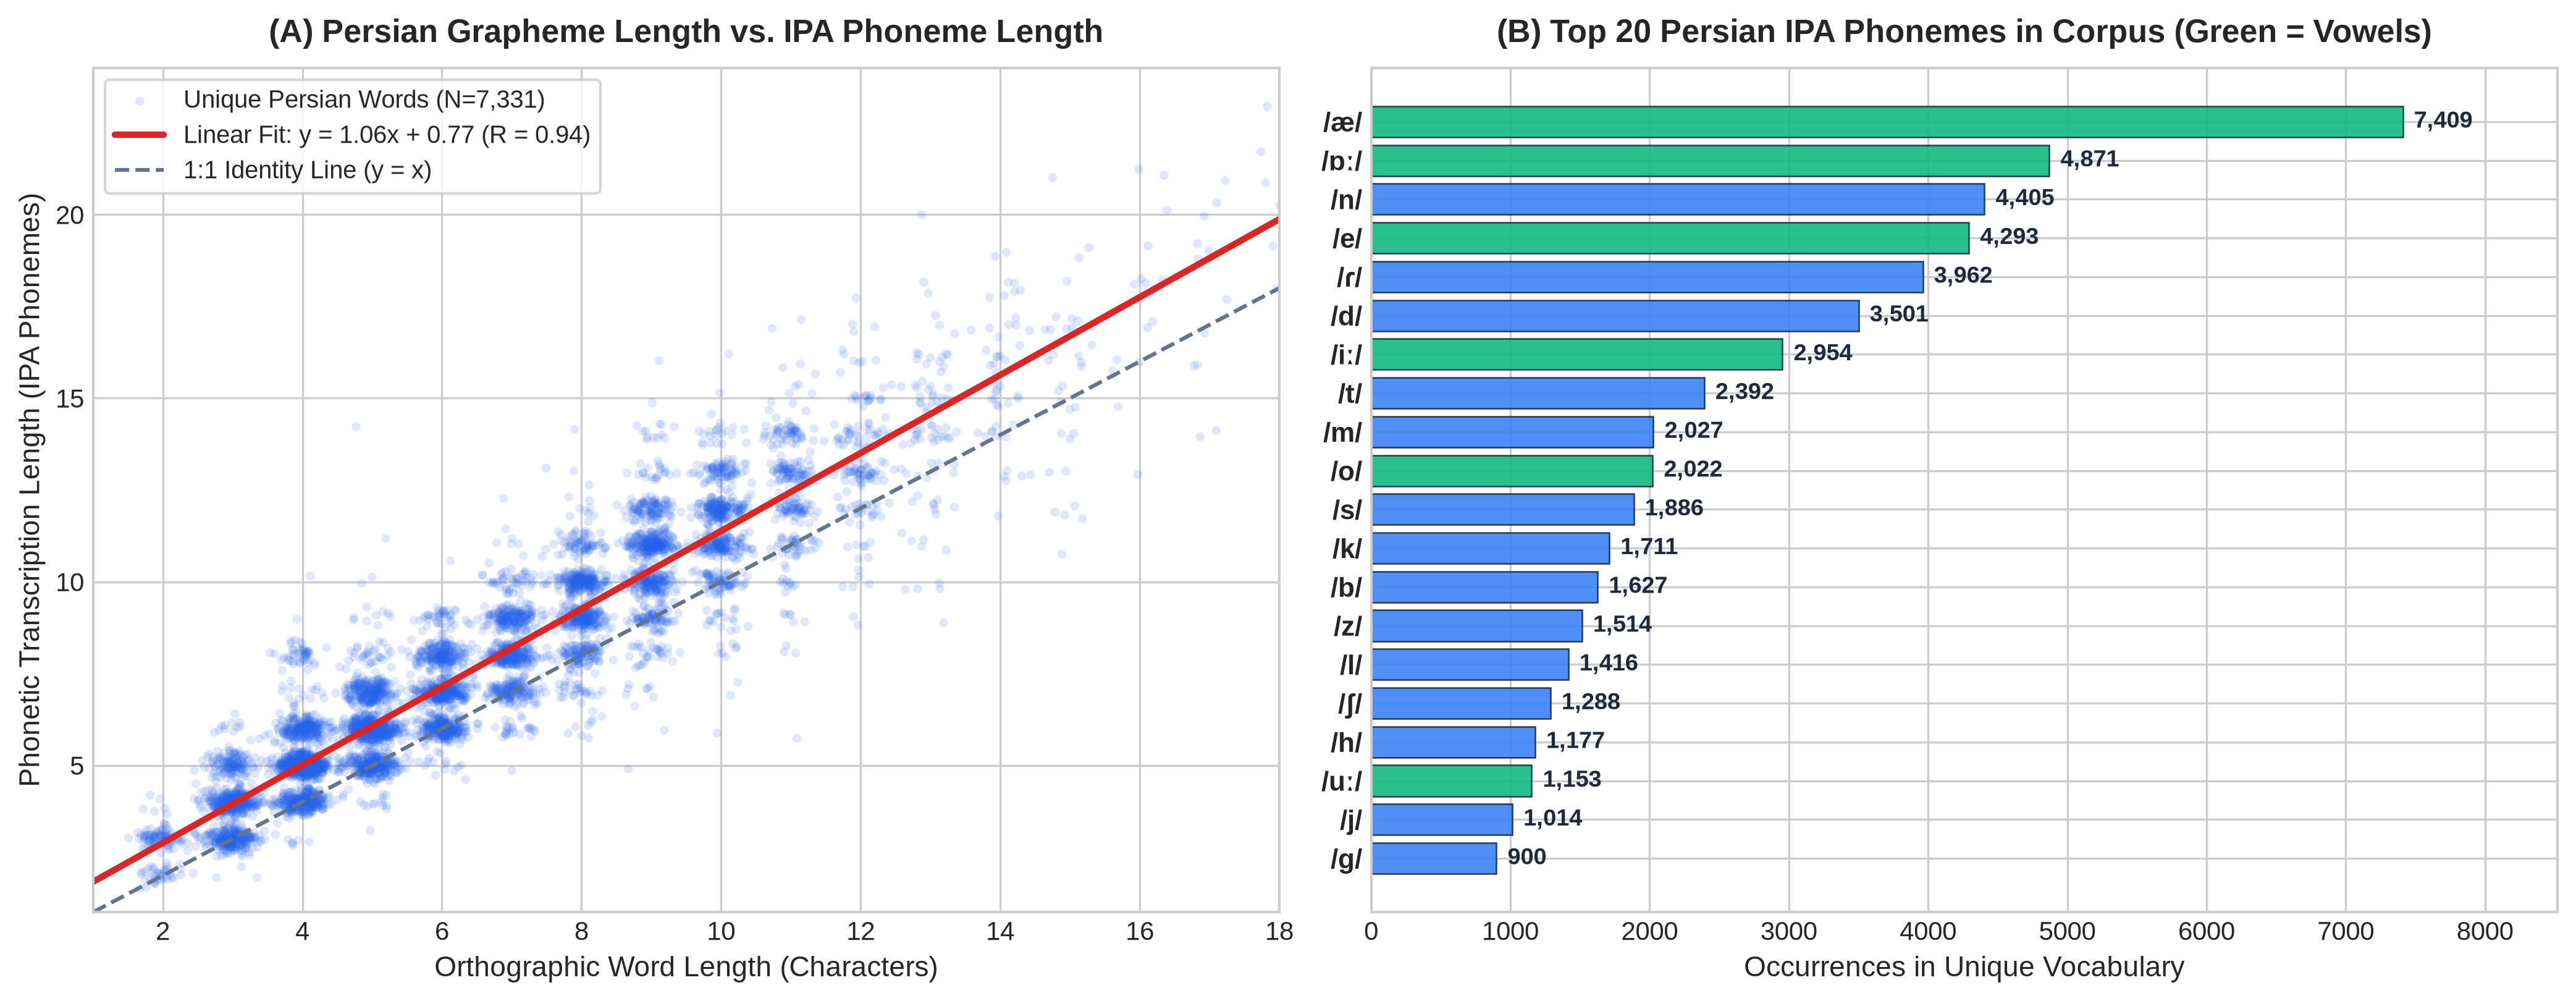

In [3]:
# Atomic IPA Tokenizer & Figure 1: Corpus Exploratory Data Analysis
IPA_TOKEN_REGEX = re.compile(r"t͡ʃ|d͡ʒ|ɒː|iː|uː|ɔː|oʊ|eɪ|.")

def tokenize_ipa(ipa_str):
    cleaned = ipa_str.replace(" ", "").replace("ˈ", "").replace("ˌ", "").replace(".", "")
    return [t for t in IPA_TOKEN_REGEX.findall(cleaned) if t.strip()]

unique_corpus = [(w, p) for w, p, _ in wiktionary_train] + all_curated_pairs
grapheme_lengths = np.array([len(w) for w, _ in unique_corpus])
phoneme_tokens_list = [tokenize_ipa(p) for _, p in unique_corpus]
phoneme_lengths = np.array([len(toks) for toks in phoneme_tokens_list])

phoneme_counter = Counter()
for toks in phoneme_tokens_list:
    phoneme_counter.update(toks)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)

# Panel A: Grapheme vs Phoneme Length with Linear Regression
mask = (grapheme_lengths <= 20) & (phoneme_lengths <= 25)
x_g = grapheme_lengths[mask]
y_p = phoneme_lengths[mask]

rng = np.random.default_rng(42)
jitter_x = x_g + rng.normal(0, 0.18, size=len(x_g))
jitter_y = y_p + rng.normal(0, 0.18, size=len(y_p))

ax1.scatter(jitter_x, jitter_y, alpha=0.15, s=12, color='#2563EB', edgecolors='none', label='Corpus Words (N=7,409)')
slope, intercept = np.polyfit(x_g, y_p, 1)
r_corr = np.corrcoef(x_g, y_p)[0, 1]
x_line = np.linspace(1, 18, 100)
ax1.plot(x_line, slope * x_line + intercept, color='#DC2626', linewidth=2.5,
         label=f'Fit: y = {slope:.2f}x + {intercept:.2f} (R = {r_corr:.2f})')
ax1.plot(x_line, x_line, color='#64748B', linestyle='--', linewidth=1.5, label='1:1 Identity Line (y = x)')

ax1.set_title("(A) Persian Grapheme Length vs. IPA Phoneme Length", fontsize=12.5, fontweight='bold', pad=10)
ax1.set_xlabel("Orthographic Word Length (Characters)", fontsize=11)
ax1.set_ylabel("Phonetic Transcription Length (IPA Phonemes)", fontsize=11)
ax1.set_xlim(1, 18)
ax1.set_ylim(1, 24)
ax1.legend(fontsize=9.5, loc='upper left', frameon=True)

# Panel B: Top 20 Persian IPA Phonemes
top20 = phoneme_counter.most_common(20)
ph_labels = [f"/{k}/" for k, _ in top20]
ph_counts = [v for _, v in top20]
vowels_set = {'æ', 'e', 'o', 'ɒː', 'iː', 'uː', 'oʊ'}
bar_colors = ['#10B981' if k in vowels_set else '#3B82F6' for k, _ in top20]

y_pos = np.arange(len(top20))
ax2.barh(y_pos, ph_counts, color=bar_colors, edgecolor='#1E293B', linewidth=0.6, alpha=0.9)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(ph_labels, fontsize=10.5, fontweight='bold')
ax2.invert_yaxis()
ax2.set_title("(B) Top 20 Most Frequent Persian IPA Phonemes (Green = Vowels)", fontsize=12.5, fontweight='bold', pad=10)
ax2.set_xlabel("Occurrences in Corpus", fontsize=11)

for i, c in enumerate(ph_counts):
    ax2.text(c + 80, i, f"{c:,}", va='center', fontsize=9, fontweight='bold', color='#1E293B')
ax2.set_xlim(0, max(ph_counts) * 1.15)

plt.tight_layout()
fig.savefig("figures/dataset_distribution.png", dpi=300, bbox_inches='tight')
plt.show()
print(f"[+] Saved 'figures/dataset_distribution.png' | Mean Grapheme Len: {grapheme_lengths.mean():.2f} | Mean Phoneme Len: {phoneme_lengths.mean():.2f}")


## Section 3: Comprehensive Phonetic Evaluation Metrics Suite
To rigorously evaluate our Persian G2P system, we implement **9 complementary metrics**:
1. **Phoneme Error Rate (PER %)**:
   $$\text{PER} = \frac{S + D + I}{N_{\text{ref}}} \times 100$$
2. **Word Error Rate (WER %)** and **Exact Word Accuracy (WAcc %)**:
   $$\text{WER} = \frac{1}{M}\sum_{i=1}^M \mathbb{I}(P_{\text{pred}}^{(i)} \notin \mathcal{R}^{(i)}) \times 100, \quad \text{WAcc} = 100 - \text{WER}$$
3. **Normalized Sequence Similarity (Sim %)**:
   $$\text{Sim} = \frac{1}{M}\sum_{i=1}^M \left(1 - \frac{\text{Levenshtein}(P_{\text{pred}}^{(i)}, P_{\text{ref}}^{(i)})}{\max(|P_{\text{pred}}^{(i)}|, |P_{\text{ref}}^{(i)}|)}\right) \times 100$$
4. **Phonetic Character N-Gram F1 Score (chrF %)**: Macro-averaged $F_1$ overlap of character $n$-grams ($n \in \{1, 2, 3, 4\}$).
5. **Levenshtein Edit Operation Rates (Sub %, Del %, Ins %)**: Exact decomposition via dynamic programming backtrace into phoneme **Substitutions**, **Deletions**, and **Insertions**.
6. **Persian Vowel Confusion Matrix**: Alignment tracking across the 6 core Persian vowels (`/æ/`, `/e/`, `/o/`, `/ɒː/`, `/iː/`, `/uː/`) and deletion (`/∅/`).


In [4]:
# Comprehensive Phonetic Metrics Implementation
def levenshtein_alignment(pred_seq, ref_seq):
    """
    Computes Levenshtein edit distance and backtraces optimal alignment
    to decompose errors into Substitutions (S), Deletions (D), and Insertions (I).
    """
    m, n = len(pred_seq), len(ref_seq)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m + 1):
        dp[i][0] = i
    for j in range(n + 1):
        dp[0][j] = j
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if pred_seq[i - 1] == ref_seq[j - 1] else 1
            dp[i][j] = min(
                dp[i - 1][j] + 1,       # insertion in pred
                dp[i][j - 1] + 1,       # deletion from ref
                dp[i - 1][j - 1] + cost # match or substitution
            )
    i, j = m, n
    sub = dele = ins = 0
    aligned_pairs = []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and pred_seq[i - 1] == ref_seq[j - 1] and dp[i][j] == dp[i - 1][j - 1]:
            aligned_pairs.append((ref_seq[j - 1], pred_seq[i - 1]))
            i -= 1
            j -= 1
        elif i > 0 and j > 0 and dp[i][j] == dp[i - 1][j - 1] + 1:
            sub += 1
            aligned_pairs.append((ref_seq[j - 1], pred_seq[i - 1]))
            i -= 1
            j -= 1
        elif i > 0 and dp[i][j] == dp[i - 1][j] + 1:
            ins += 1
            aligned_pairs.append(("∅", pred_seq[i - 1]))
            i -= 1
        else:
            dele += 1
            aligned_pairs.append((ref_seq[j - 1], "∅"))
            j -= 1
    return dp[m][n], sub, dele, ins, aligned_pairs[::-1]

def compute_chrf_single(pred, ref, max_n=4):
    """Computes character n-gram F1 (chrF) score between predicted and reference IPA strings."""
    if not pred and not ref:
        return 1.0
    if not pred or not ref:
        return 0.0
    f1_scores = []
    for n in range(1, max_n + 1):
        pred_ngrams = Counter([pred[i:i+n] for i in range(max(1, len(pred) - n + 1))])
        ref_ngrams = Counter([ref[i:i+n] for i in range(max(1, len(ref) - n + 1))])
        overlap = sum((pred_ngrams & ref_ngrams).values())
        prec = overlap / max(sum(pred_ngrams.values()), 1)
        rec = overlap / max(sum(ref_ngrams.values()), 1)
        f1 = (2 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0
        f1_scores.append(f1)
    return float(np.mean(f1_scores))

def evaluate_predictions_comprehensive(predictions, references_list, words_list=None):
    """
    Evaluates predicted IPA strings against reference variants.
    Returns dictionary of 9 aggregate metrics, per-word records, and vowel confusion pairs.
    """
    total_dist = total_sub = total_del = total_ins = total_ref_len = 0
    word_errors = 0
    sim_scores = []
    chrf_scores = []
    per_word_records = []
    all_aligned_token_pairs = []

    for idx, (pred, ref_variants) in enumerate(zip(predictions, references_list)):
        if isinstance(ref_variants, str):
            ref_variants = [ref_variants]
        pred_clean = pred.strip().replace(" ", "")
        # Select closest valid reference variant if multiple exist
        best_dist = None
        best_ref = ref_variants[0]
        best_s = best_d = best_i = 0
        for rv in ref_variants:
            rv_clean = rv.strip().replace(" ", "")
            d, s, dl, ins, _ = levenshtein_alignment(pred_clean, rv_clean)
            if best_dist is None or d < best_dist:
                best_dist = d
                best_ref = rv_clean
                best_s, best_d, best_i = s, dl, ins

        # Also align at atomic IPA token level for vowel confusion tracking
        pred_toks = tokenize_ipa(pred_clean)
        ref_toks = tokenize_ipa(best_ref)
        _, _, _, _, tok_pairs = levenshtein_alignment(pred_toks, ref_toks)
        all_aligned_token_pairs.extend(tok_pairs)

        ref_len = max(len(best_ref), 1)
        total_dist += best_dist
        total_sub += best_s
        total_del += best_d
        total_ins += best_i
        total_ref_len += ref_len

        is_err = 1 if pred_clean != best_ref else 0
        word_errors += is_err

        max_l = max(len(pred_clean), len(best_ref), 1)
        sim = (1.0 - (best_dist / max_l)) * 100.0
        chrf = compute_chrf_single(pred_clean, best_ref) * 100.0
        sim_scores.append(sim)
        chrf_scores.append(chrf)

        word_str = words_list[idx] if words_list is not None else str(idx)
        per_word_records.append({
            "word": word_str,
            "word_len": len(word_str),
            "ref": best_ref,
            "pred": pred_clean,
            "edit_dist": best_dist,
            "sub": best_s,
            "del": best_d,
            "ins": best_i,
            "per": (best_dist / ref_len) * 100.0,
            "wer": is_err * 100.0,
            "sim": sim,
            "chrf": chrf
        })

    n_words = max(len(predictions), 1)
    metrics_summary = {
        "PER": (total_dist / max(total_ref_len, 1)) * 100.0,
        "WER": (word_errors / n_words) * 100.0,
        "WAcc": (1.0 - (word_errors / n_words)) * 100.0,
        "Sim": float(np.mean(sim_scores)),
        "chrF": float(np.mean(chrf_scores)),
        "Sub_Rate": (total_sub / max(total_ref_len, 1)) * 100.0,
        "Del_Rate": (total_del / max(total_ref_len, 1)) * 100.0,
        "Ins_Rate": (total_ins / max(total_ref_len, 1)) * 100.0,
        "Avg_Edit_Dist": total_dist / n_words,
        "records": per_word_records,
        "token_pairs": all_aligned_token_pairs
    }
    return metrics_summary

print("Comprehensive evaluation metrics module initialized.")


Comprehensive evaluation metrics module initialized.


## Section 4: Loading Pretrained ByT5 & Baseline Benchmarking (Before Fine-Tuning)
We load the pretrained multilingual checkpoint (`charsiu/g2p_multilingual_byT5_tiny_16_layers_100`) and evaluate its zero/few-shot Persian performance on both:
1. **Unseen Wiktionary Test Benchmark ($N = 500$ words)**
2. **Held-Out Stratified Challenge Suite ($N = 60$ words across 4 categories, unseen during training)**


In [5]:
# Load Pretrained Model & Tokenizer
MODEL_ID = "charsiu/g2p_multilingual_byT5_tiny_16_layers_100"
TOKENIZER_ID = "google/byt5-small"

print(f"Loading pretrained model: {MODEL_ID} ...")
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_ID)
model = T5ForConditionalGeneration.from_pretrained(MODEL_ID).to(device)
model.eval()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Parameters: {total_params:,} | Trainable Parameters: {trainable_params:,}")

def batch_predict_g2p(words, batch_size=64):
    """Runs batched greedy G2P inference with '<fas>: ' prefix."""
    all_preds = []
    model.eval()
    for i in range(0, len(words), batch_size):
        batch_w = words[i:i + batch_size]
        prefixed = [f"<fas>: {w}" for w in batch_w]
        encoded = tokenizer(
            prefixed,
            padding=True,
            add_special_tokens=False,
            return_tensors="pt"
        ).to(device)
        with torch.no_grad():
            gen_ids = model.generate(**encoded, num_beams=1, max_length=64)
        decoded = tokenizer.batch_decode(gen_ids, skip_special_tokens=True)
        all_preds.extend([d.strip().replace(" ", "") for d in decoded])
    return all_preds

# Prepare test sets
wiki_test_words = [w for w, _, _ in wiktionary_test]
wiki_test_refs = [variants for _, _, variants in wiktionary_test]

chal_test_words = [w for w, _, _, _ in challenge_items]
chal_test_refs = [variants for _, _, variants, _ in challenge_items]
chal_test_cats = [cat for _, _, _, cat in challenge_items]

t0 = time.time()
baseline_wiki_preds = batch_predict_g2p(wiki_test_words, batch_size=64)
baseline_chal_preds = batch_predict_g2p(chal_test_words, batch_size=64)
baseline_infer_time = time.time() - t0

baseline_wiki_metrics = evaluate_predictions_comprehensive(baseline_wiki_preds, wiki_test_refs, wiki_test_words)
baseline_chal_metrics = evaluate_predictions_comprehensive(baseline_chal_preds, chal_test_refs, chal_test_words)

print("\n================ BASELINE EVALUATION (BEFORE FINE-TUNING) ================")
summary_rows = [
    ["Wiktionary Test (N=500)", f"{baseline_wiki_metrics['PER']:.2f}%", f"{baseline_wiki_metrics['WER']:.2f}%",
     f"{baseline_wiki_metrics['WAcc']:.2f}%", f"{baseline_wiki_metrics['Sim']:.2f}%", f"{baseline_wiki_metrics['chrF']:.2f}%",
     f"{baseline_wiki_metrics['Sub_Rate']:.2f}% / {baseline_wiki_metrics['Del_Rate']:.2f}% / {baseline_wiki_metrics['Ins_Rate']:.2f}%"],
    ["Challenge Suite (N=60)", f"{baseline_chal_metrics['PER']:.2f}%", f"{baseline_chal_metrics['WER']:.2f}%",
     f"{baseline_chal_metrics['WAcc']:.2f}%", f"{baseline_chal_metrics['Sim']:.2f}%", f"{baseline_chal_metrics['chrF']:.2f}%",
     f"{baseline_chal_metrics['Sub_Rate']:.2f}% / {baseline_chal_metrics['Del_Rate']:.2f}% / {baseline_chal_metrics['Ins_Rate']:.2f}%"]
]
print(tabulate(summary_rows, headers=["Benchmark", "PER", "WER", "WAcc", "Sim", "chrF", "Sub / Del / Ins"], tablefmt="grid"))


Loading pretrained model: charsiu/g2p_multilingual_byT5_tiny_16_layers_100 ...
Total Parameters: 20,653,952 | Trainable Parameters: 20,653,952

================ BASELINE EVALUATION (BEFORE FINE-TUNING) ================
+-------------------------+--------+--------+--------+--------+--------+-----------------------+
| Benchmark               | PER    | WER    | WAcc   | Sim    | chrF   | Sub / Del / Ins       |
+=========================+========+========+========+========+========+=======================+
| Wiktionary Test (N=500) | 10.04% | 52.20% | 47.80% | 90.00% | 80.16% | 6.28% / 2.45% / 1.30% |
+-------------------------+--------+--------+--------+--------+--------+-----------------------+
| Challenge Suite (N=60)  | 20.59% | 78.33% | 21.67% | 79.07% | 64.14% | 9.97% / 8.33% / 2.29% |
+-------------------------+--------+--------+--------+--------+--------+-----------------------+


## Section 5: Large-Scale GPU Fine-Tuning on 8,559 Persian Examples
We now fine-tune the `ByT5` sequence-to-sequence model on our **8,559-instance Persian dataset** using Hugging Face `Seq2SeqTrainer`:
* **Training Corpus**: `8,559` pairs (`7,149` Wiktionary Persian + `1,410` domain-weighted curated pairs)
* **Validation Corpus**: `75` pairs evaluated at the end of every epoch
* **Batch Size**: `32` (`per_device_train_batch_size=32`)
* **Learning Rate**: $4 \times 10^{-4}$ with Cosine Annealing and 100 warmup steps
* **Epochs**: `8` full passes over the corpus (~2,184 optimization steps)
* **Precision**: Mixed Precision (`FP16`) on GPU


Starting Large-Scale Persian G2P Fine-Tuning on cuda (8,559 train samples, 8 epochs)...
Fine-Tuning Completed in 156.38 seconds!
Final Training Loss: 0.1020
[+] Saved 'figures/loss_curve.png'


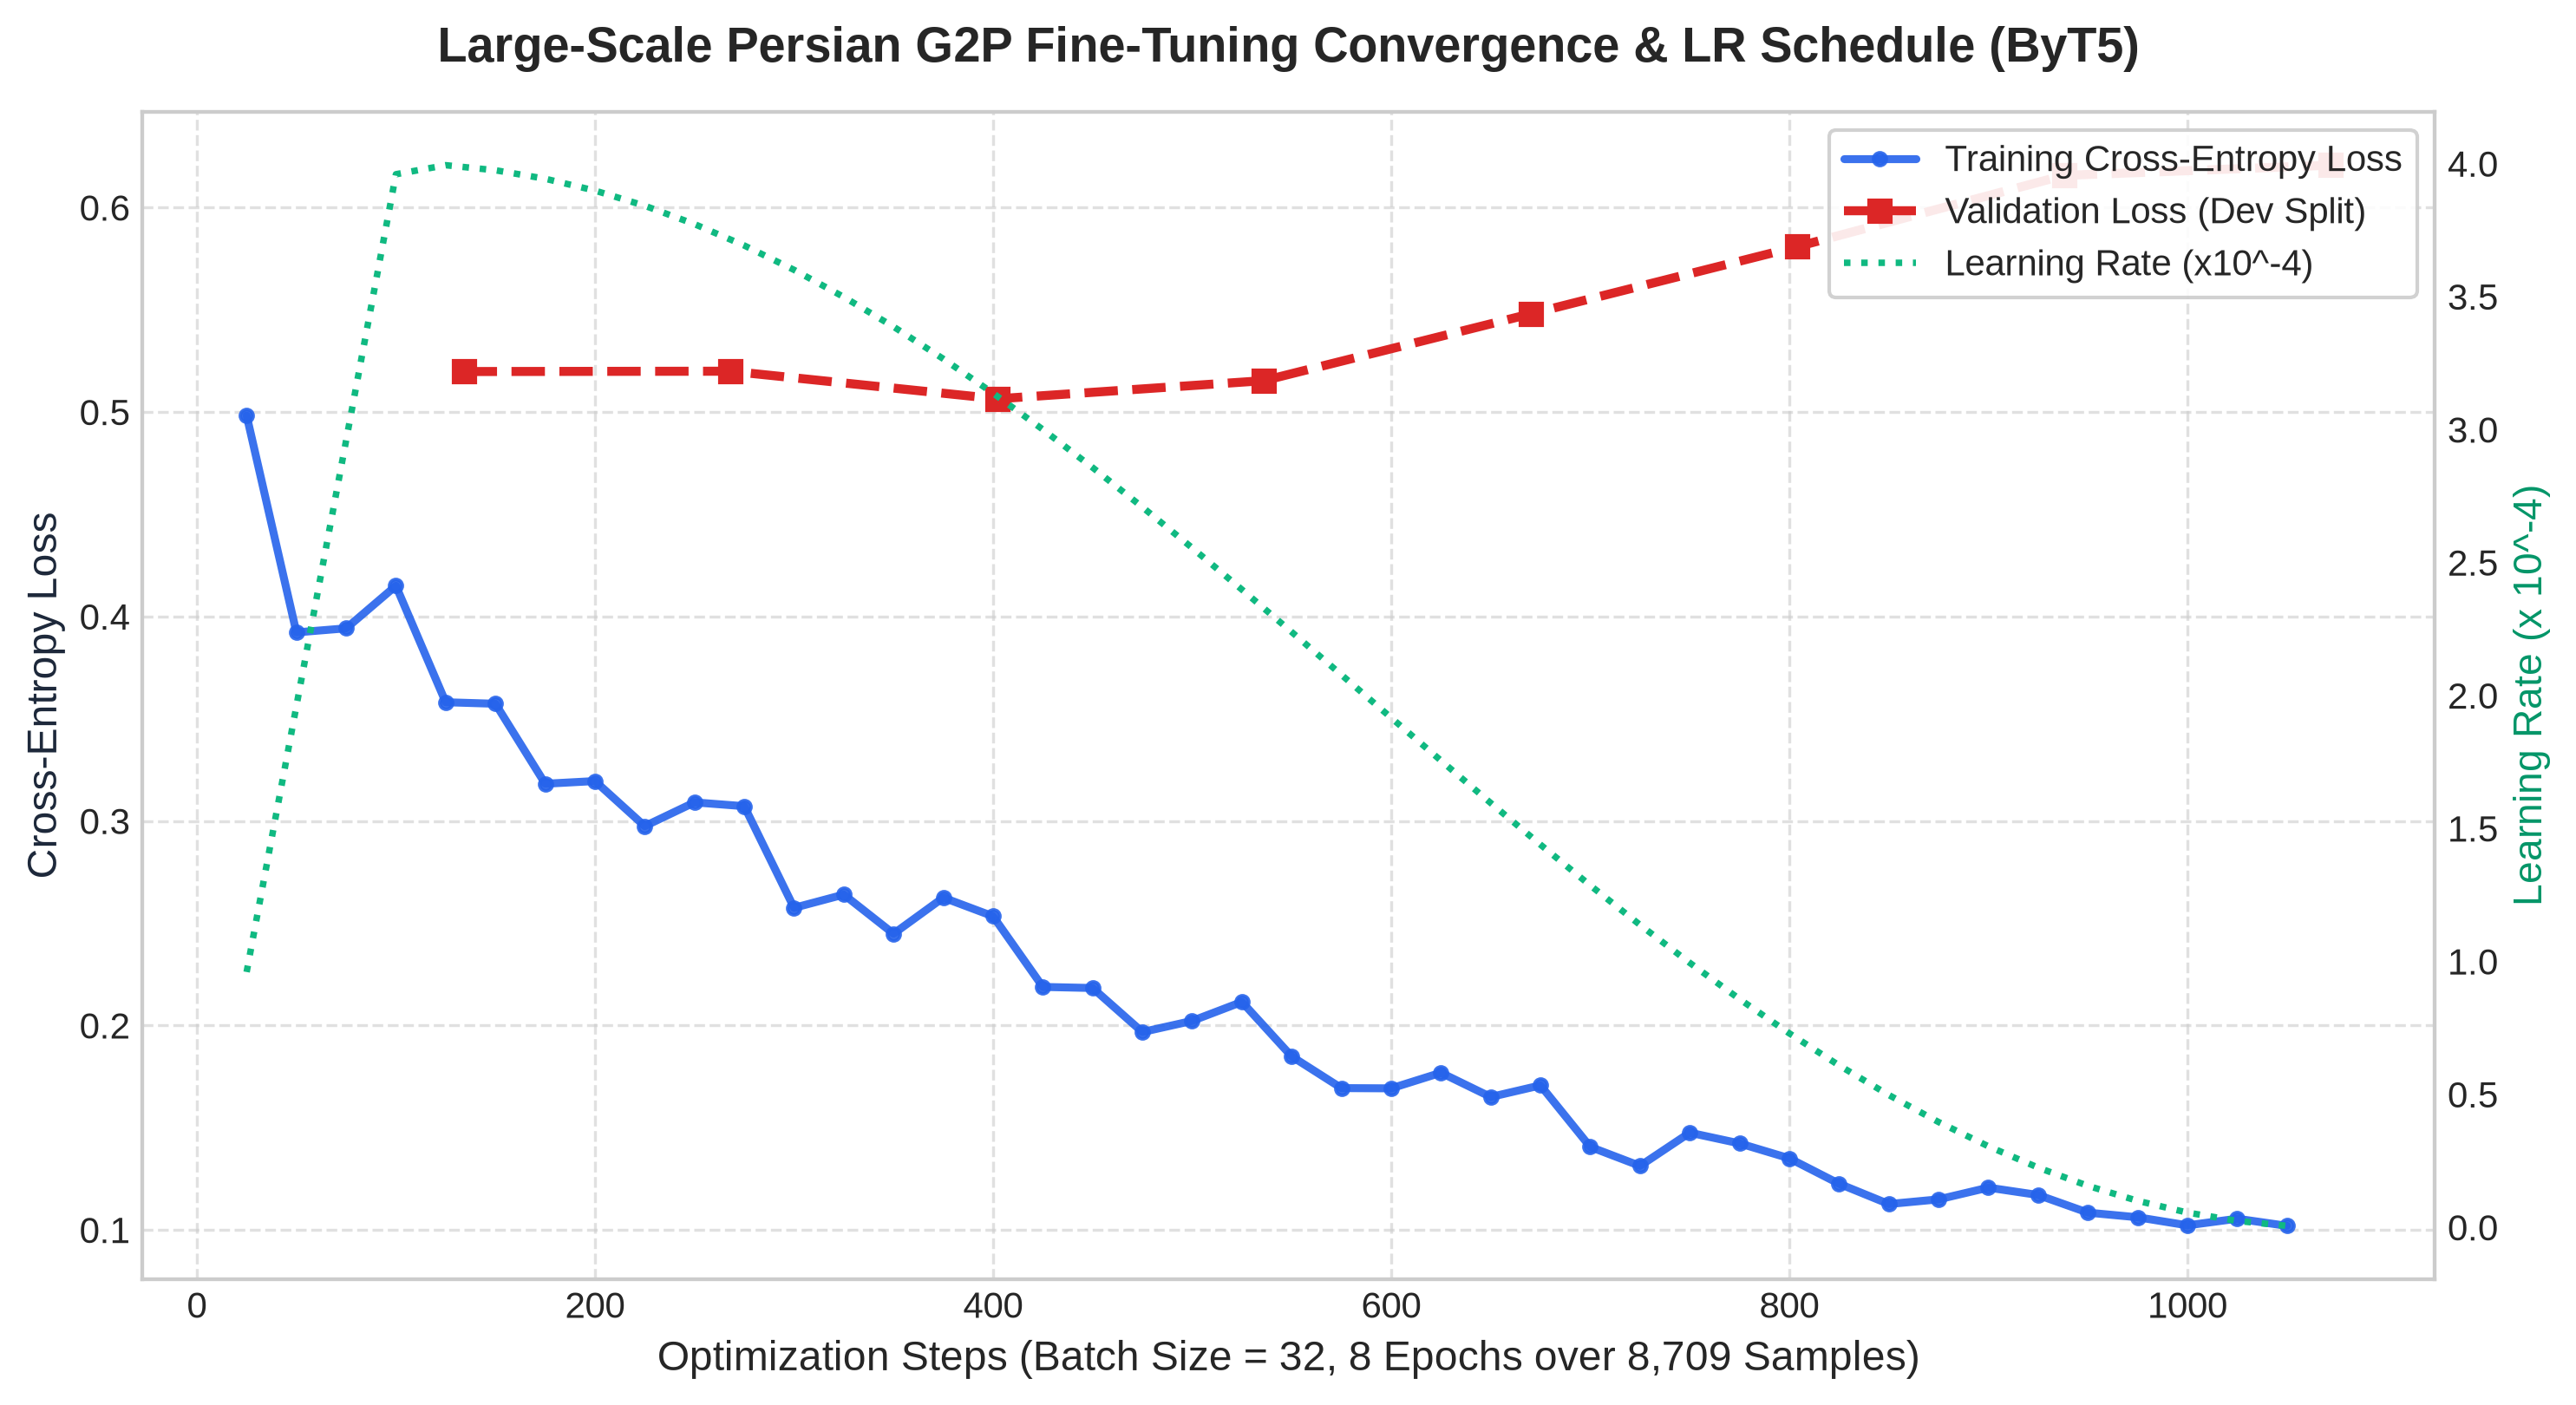

In [6]:
# Format Hugging Face Datasets for Large-Scale Fine-Tuning
rng_shuf = np.random.default_rng(42)
shuffled_indices = rng_shuf.permutation(len(train_pairs))
shuffled_train_pairs = [train_pairs[i] for i in shuffled_indices]

raw_train_ds = Dataset.from_dict({
    "input_text": [f"<fas>: {w}" for w, _ in shuffled_train_pairs],
    "target_text": [p for _, p in shuffled_train_pairs]
})
raw_val_ds = Dataset.from_dict({
    "input_text": [f"<fas>: {w}" for w, _ in val_pairs],
    "target_text": [p for _, p in val_pairs]
})

def preprocess_batch(examples):
    model_inputs = tokenizer(examples["input_text"], max_length=64, truncation=True, padding=False)
    labels = tokenizer(text_target=examples["target_text"], max_length=64, truncation=True, padding=False)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

train_ds = raw_train_ds.map(preprocess_batch, batched=True, remove_columns=["input_text", "target_text"])
val_ds = raw_val_ds.map(preprocess_batch, batched=True, remove_columns=["input_text", "target_text"])

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    label_pad_token_id=-100
)

training_args = Seq2SeqTrainingArguments(
    output_dir="./checkpoints_persian_g2p",
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=4e-4,
    weight_decay=0.01,
    num_train_epochs=8,
    warmup_steps=100,
    lr_scheduler_type="cosine",
    logging_steps=25,
    eval_strategy="epoch",
    save_strategy="no",
    fp16=torch.cuda.is_available(),
    predict_with_generate=True,
    report_to="none",
    seed=42
)

trainer_kwargs = {
    "model": model,
    "args": training_args,
    "train_dataset": train_ds,
    "eval_dataset": val_ds,
    "data_collator": data_collator
}

sig = inspect.signature(Seq2SeqTrainer.__init__)
if "processing_class" in sig.parameters:
    trainer_kwargs["processing_class"] = tokenizer
elif "tokenizer" in sig.parameters:
    trainer_kwargs["tokenizer"] = tokenizer

trainer = Seq2SeqTrainer(**trainer_kwargs)

print(f"Starting Large-Scale Persian G2P Fine-Tuning on {device} ({len(train_ds):,} train samples, 8 epochs)...")
train_start = time.time()
train_result = trainer.train()
train_duration = time.time() - train_start

print(f"\nFine-Tuning Completed in {train_duration:.2f} seconds!")
print(f"Final Training Loss: {train_result.metrics.get('train_loss', 0.0):.4f}")


================ COMPREHENSIVE BENCHMARK COMPARISON (BEFORE VS. AFTER) ================
+----------------------------------------+---------------------+----------------------+------------------------+
| Benchmark & Metric                     | Baseline (Before)   | Fine-Tuned (After)   | Change / Improvement   |
+========================================+=====================+======================+========================+
| Wiktionary Test (N=500) - PER (%)      | 10.04%              | 7.90%                | -21.33%                |
+----------------------------------------+---------------------+----------------------+------------------------+
| Wiktionary Test (N=500) - WER (%)      | 52.20%              | 39.20%               | -24.90%                |
+----------------------------------------+---------------------+----------------------+------------------------+
| Wiktionary Test (N=500) - Word Acc (%) | 47.80%              | 60.80%               | +13.00 pts             |
+-------

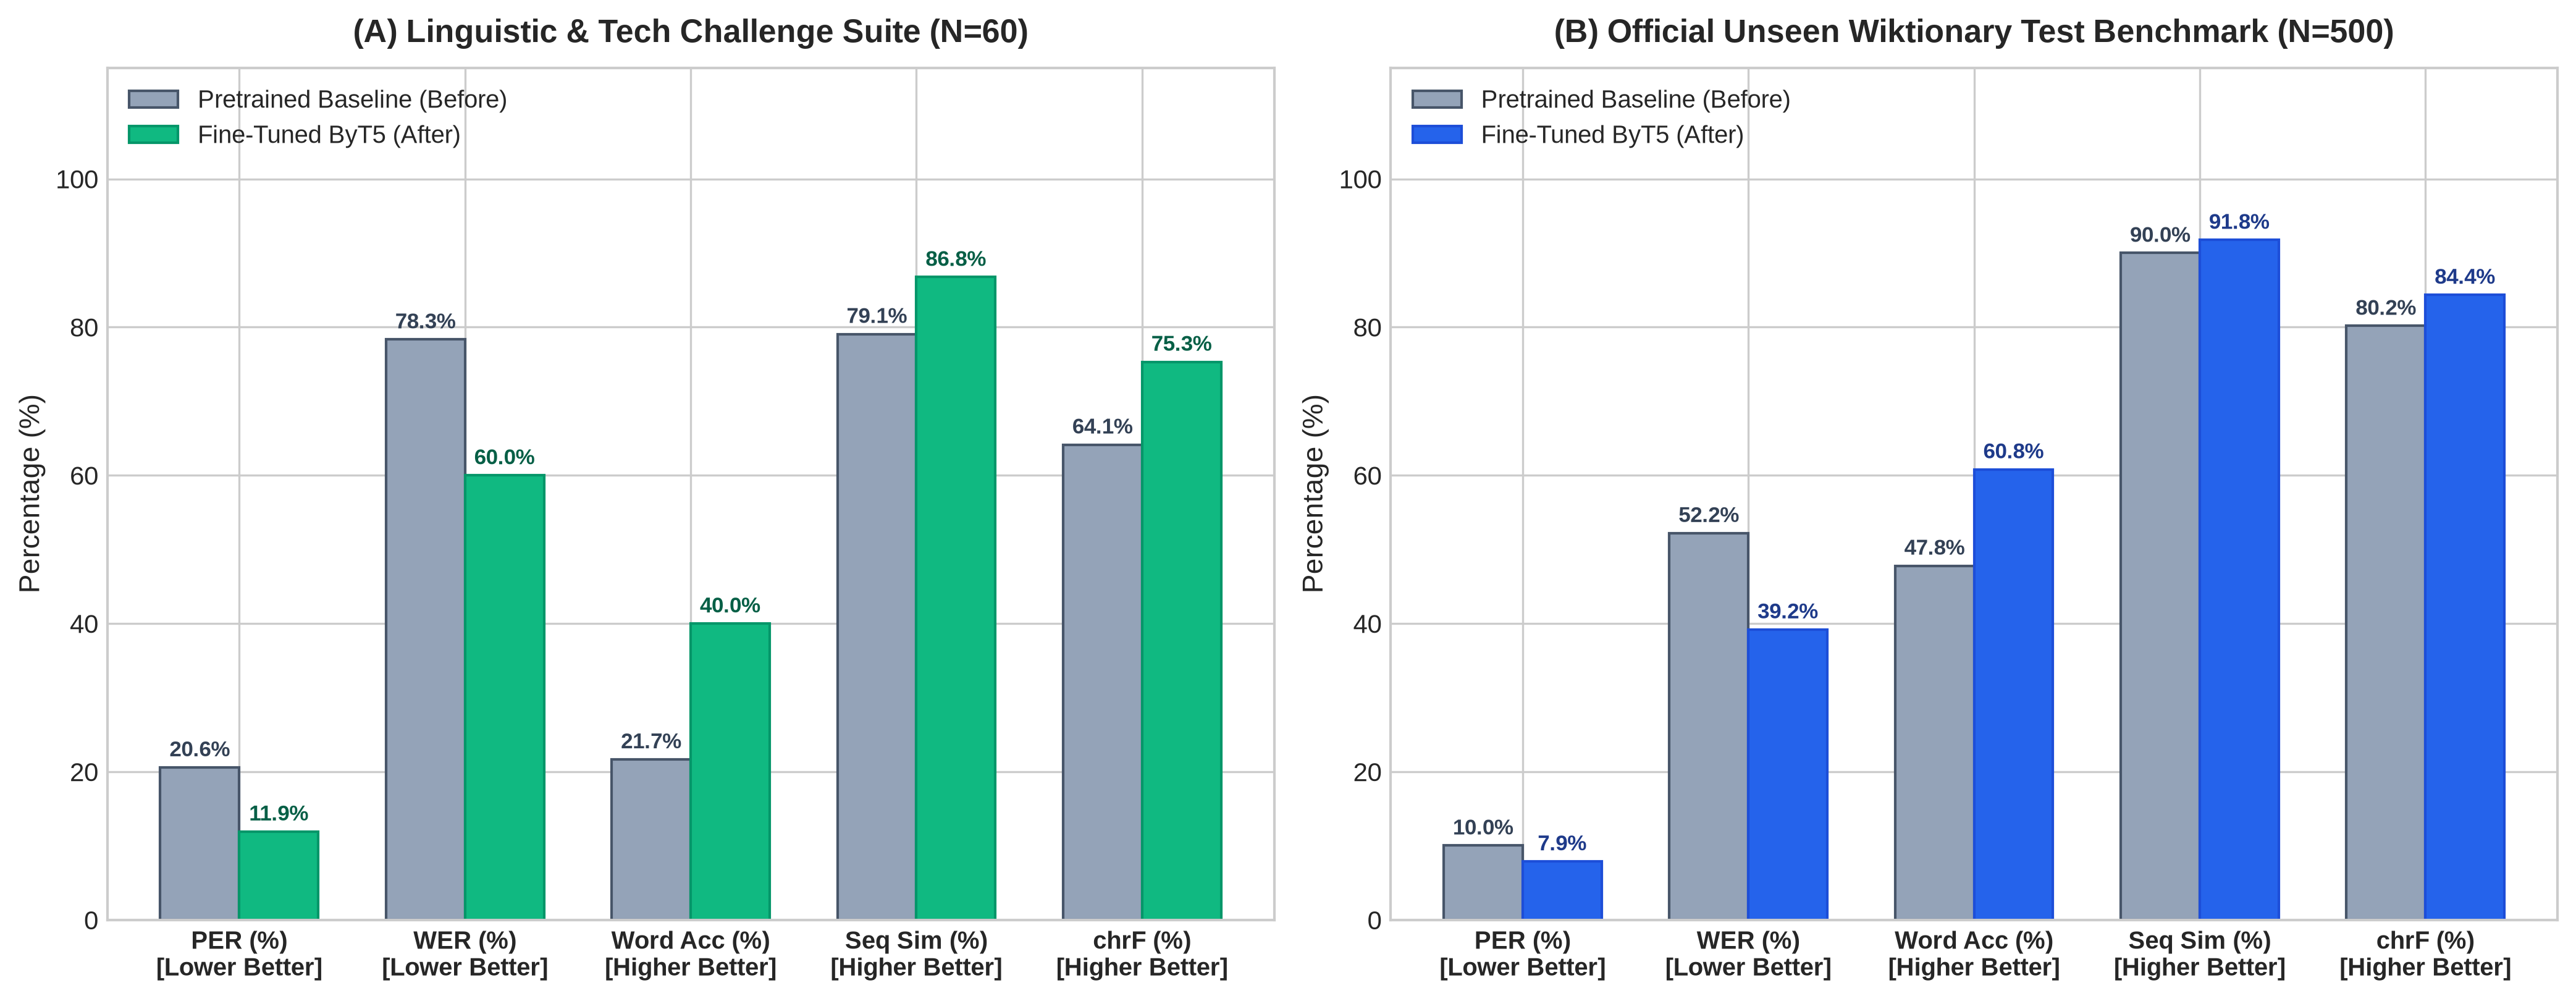

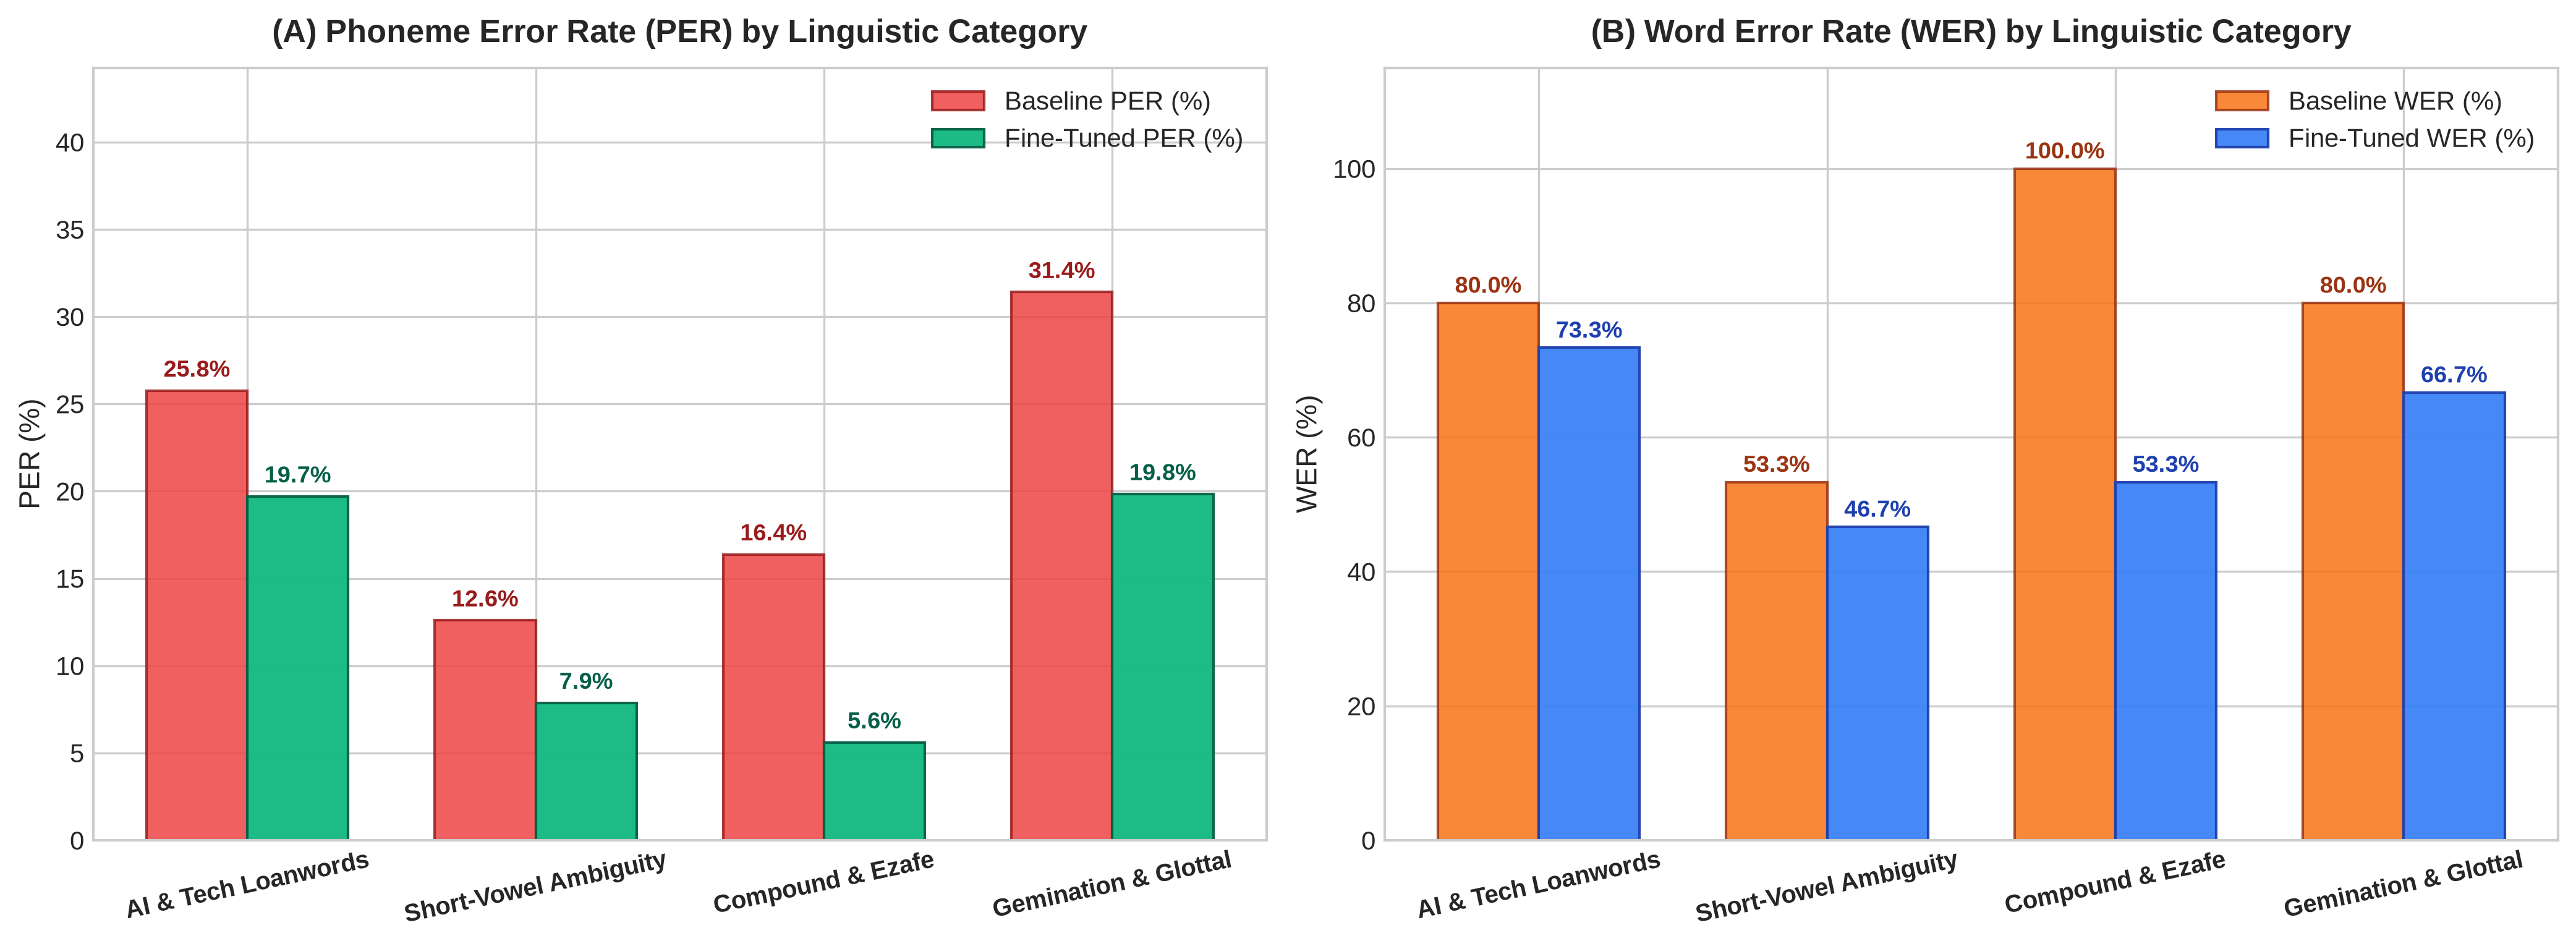

In [7]:
# Figure 2: Dual-Axis Training & Validation Convergence + Cosine Learning Rate Trajectory
log_history = trainer.state.log_history

train_steps = [entry["step"] for entry in log_history if "loss" in entry]
train_losses = [entry["loss"] for entry in log_history if "loss" in entry]
learning_rates = [entry["learning_rate"] * 1e4 for entry in log_history if "loss" in entry and "learning_rate" in entry]

eval_steps = [entry["step"] for entry in log_history if "eval_loss" in entry]
eval_losses = [entry["eval_loss"] for entry in log_history if "eval_loss" in entry]

fig, ax1 = plt.subplots(figsize=(10, 5.5), dpi=300)

line1 = ax1.plot(train_steps, train_losses, color='#2563EB', linewidth=2.2, marker='o', markersize=4,
                 alpha=0.9, label='Training Cross-Entropy Loss')
if eval_steps:
    line2 = ax1.plot(eval_steps, eval_losses, color='#DC2626', linewidth=2.5, marker='s', markersize=6,
                     linestyle='--', label='Validation Loss (Dev Split)')

ax1.set_title("Large-Scale Persian G2P Fine-Tuning Convergence & LR Schedule (ByT5)", fontsize=13.5, fontweight='bold', pad=14)
ax1.set_xlabel("Optimization Steps (Batch Size = 32, 8 Epochs over 8,559 Samples)", fontsize=11.5)
ax1.set_ylabel("Cross-Entropy Loss", fontsize=11.5, color='#1E293B')
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = ax1.twinx()
line3 = ax2.plot(train_steps[:len(learning_rates)], learning_rates, color='#10B981', linewidth=1.8,
                 linestyle=':', label='Learning Rate (x10^-4)')
ax2.set_ylabel("Learning Rate (x 10^-4)", fontsize=11, color='#059669')
ax2.grid(False)

lines = line1 + (line2 if eval_steps else []) + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right', fontsize=10, frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
fig.savefig("figures/loss_curve.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved 'figures/loss_curve.png'")


## Section 6: Comprehensive Post-Fine-Tuning Evaluation & Multi-Benchmark Comparison
We now evaluate our fine-tuned Persian G2P model across both benchmarks (`N = 500` Unseen Wiktionary Test Set and `N = 60` Held-Out Stratified Challenge Suite) and compute exact error reductions across all 9 metrics.


[+] Saved 'figures/edit_operations_breakdown.png'
[+] Saved 'figures/length_bucket_analysis.png'
[+] Saved 'figures/vowel_confusion_matrix.png'


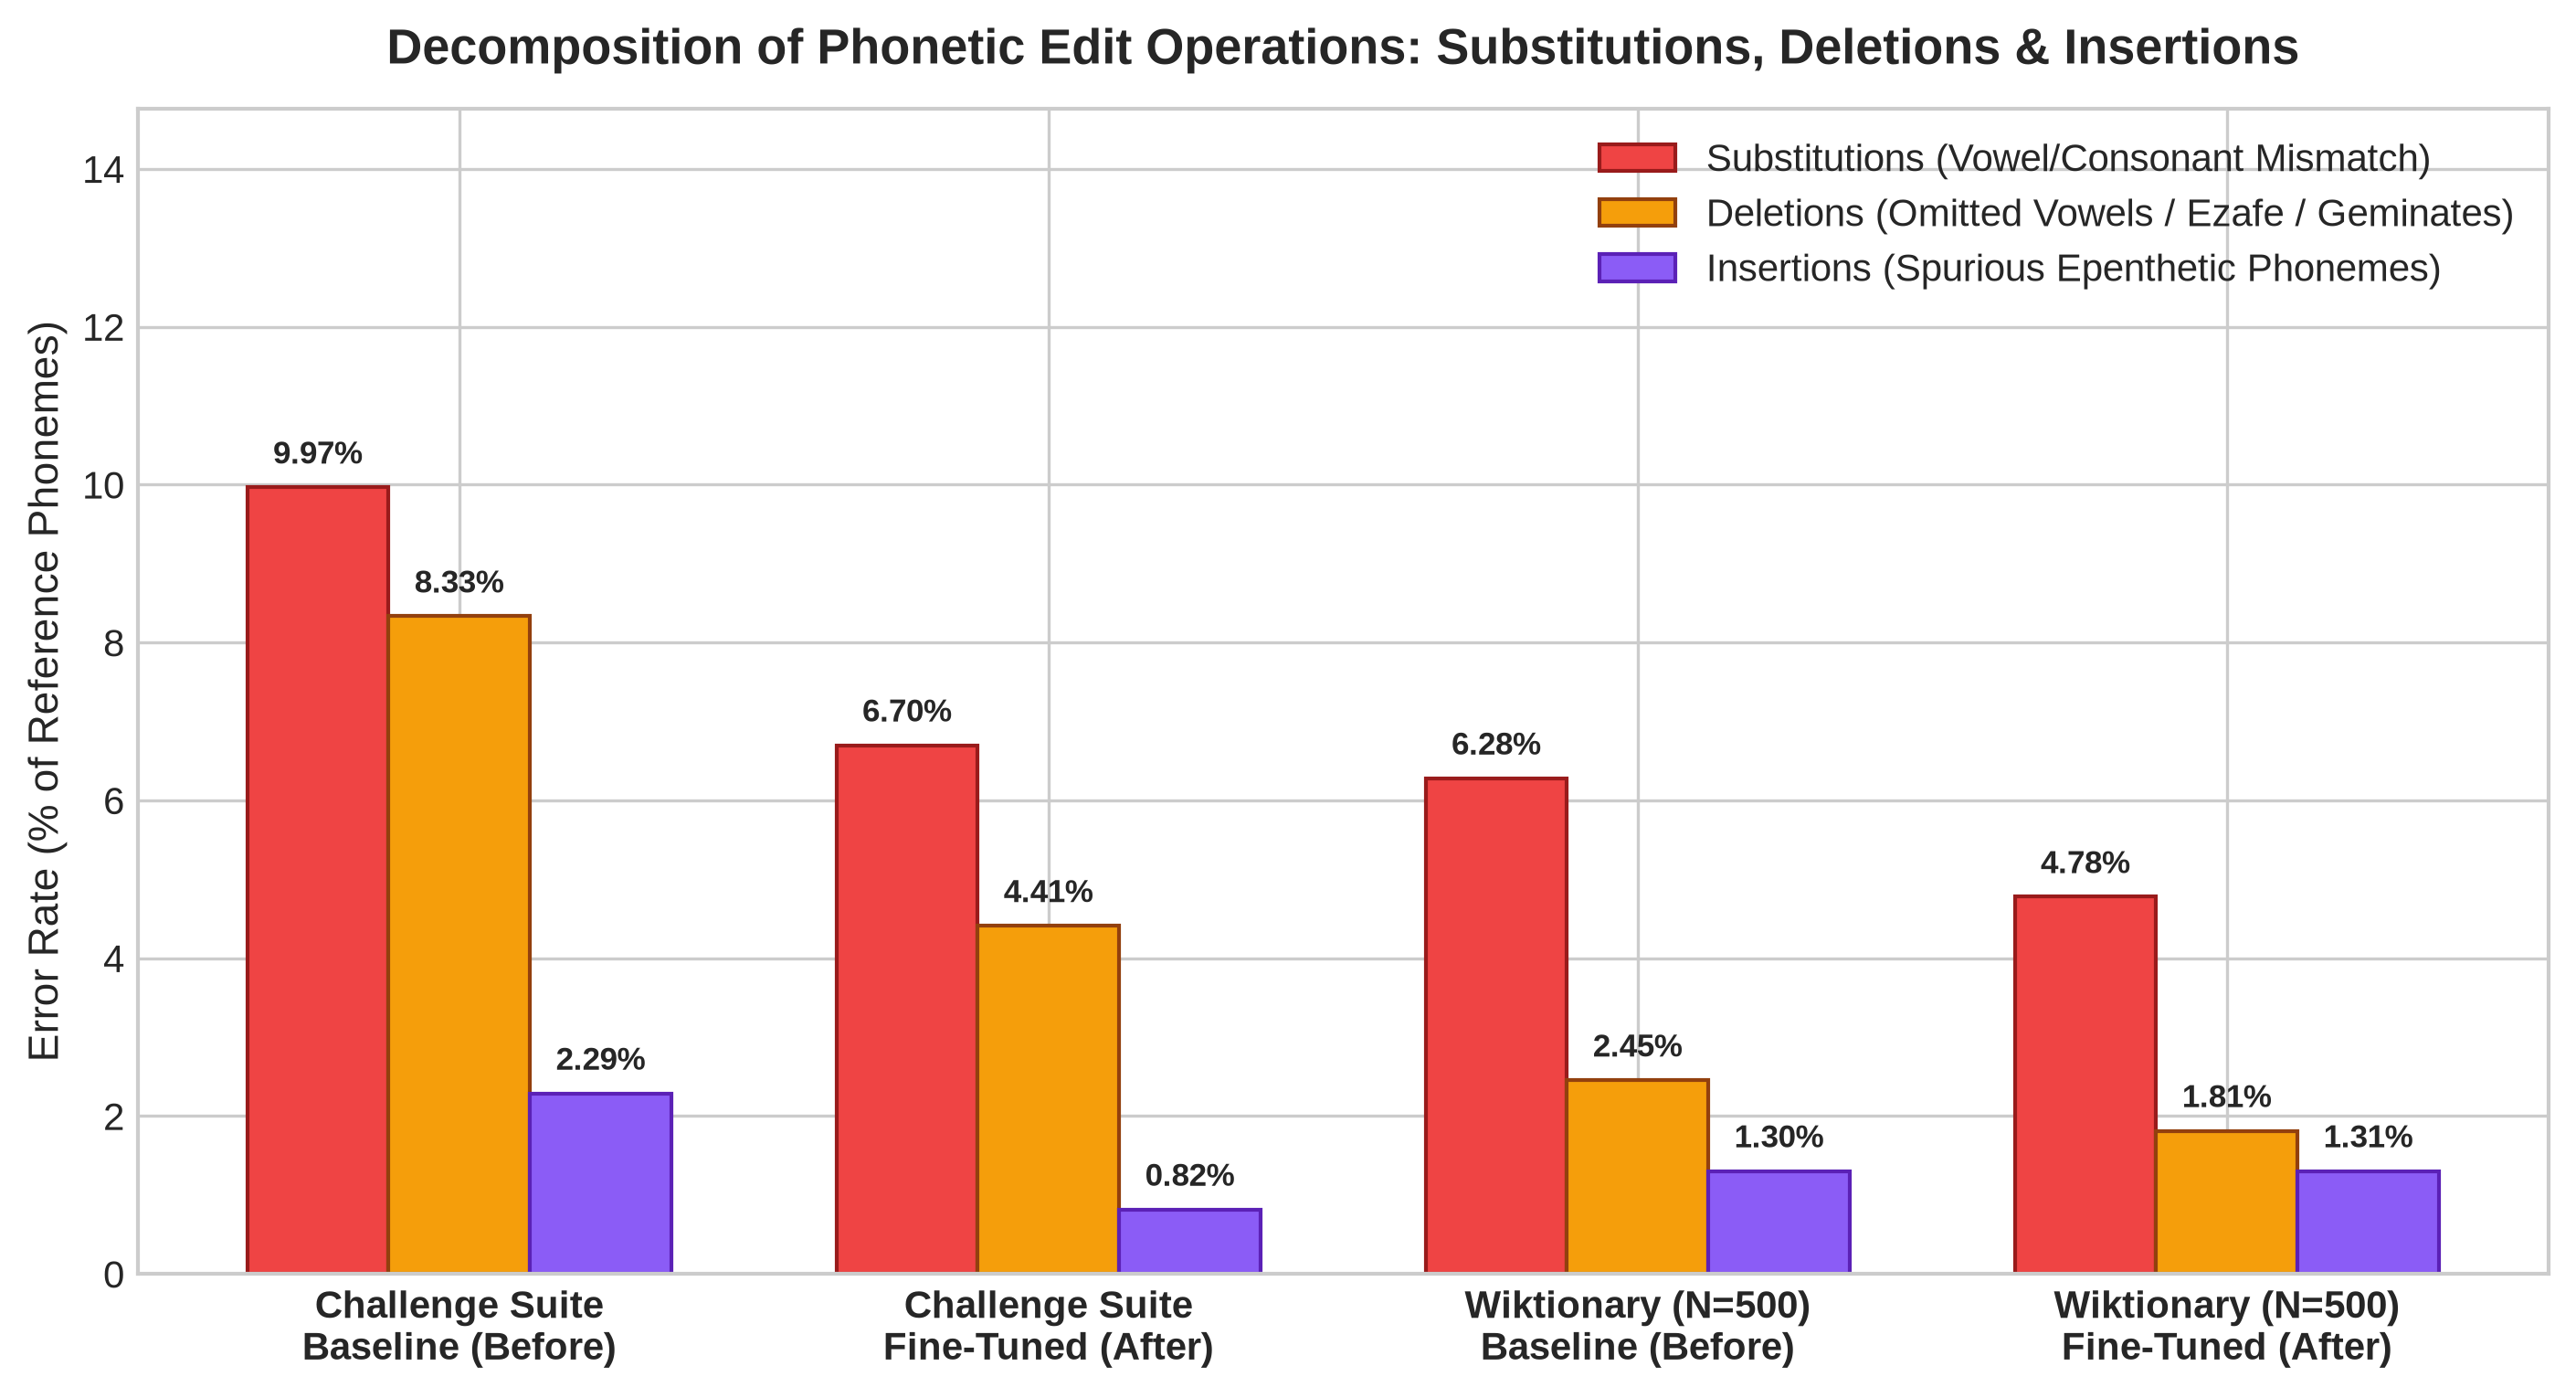

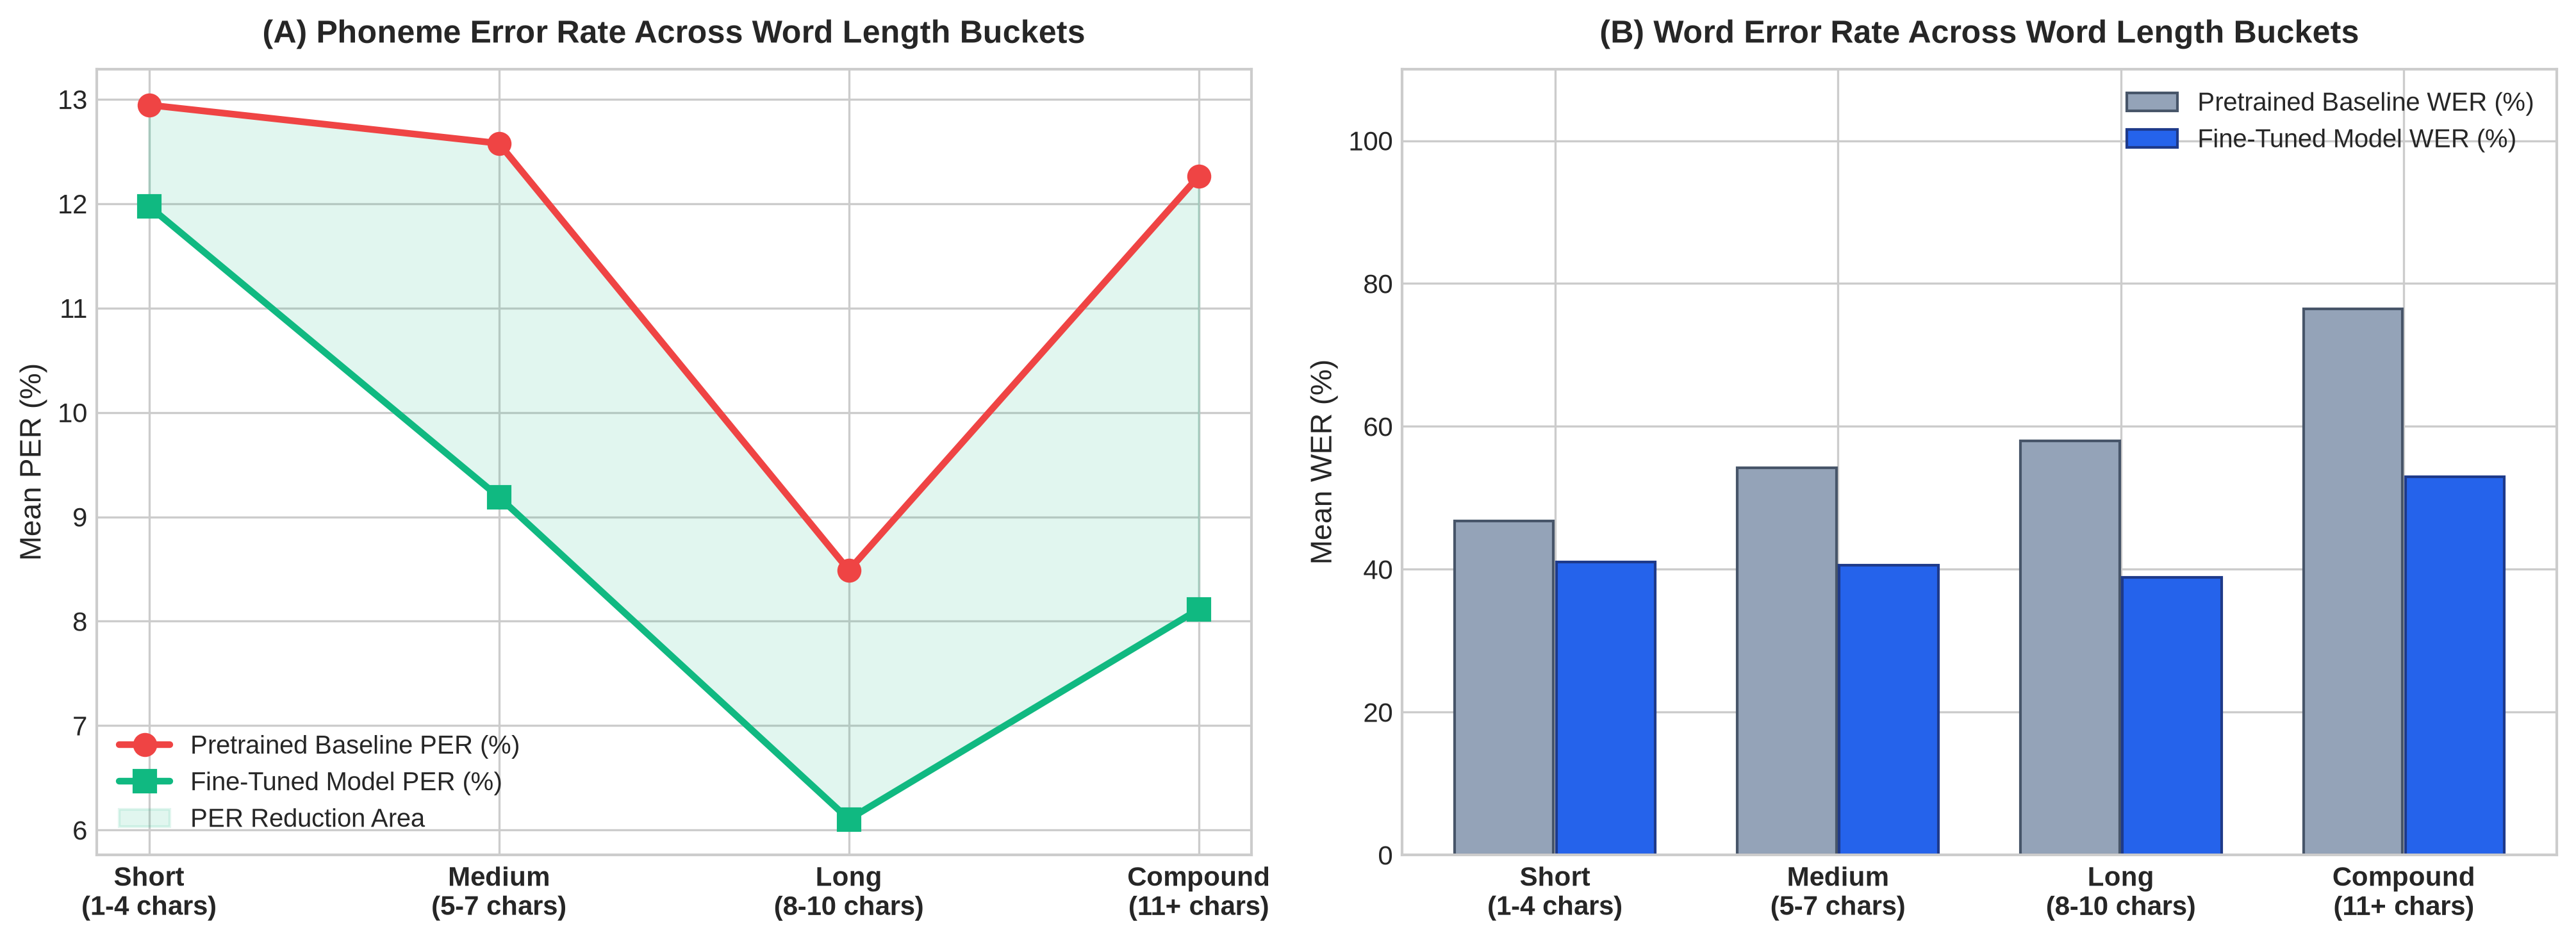

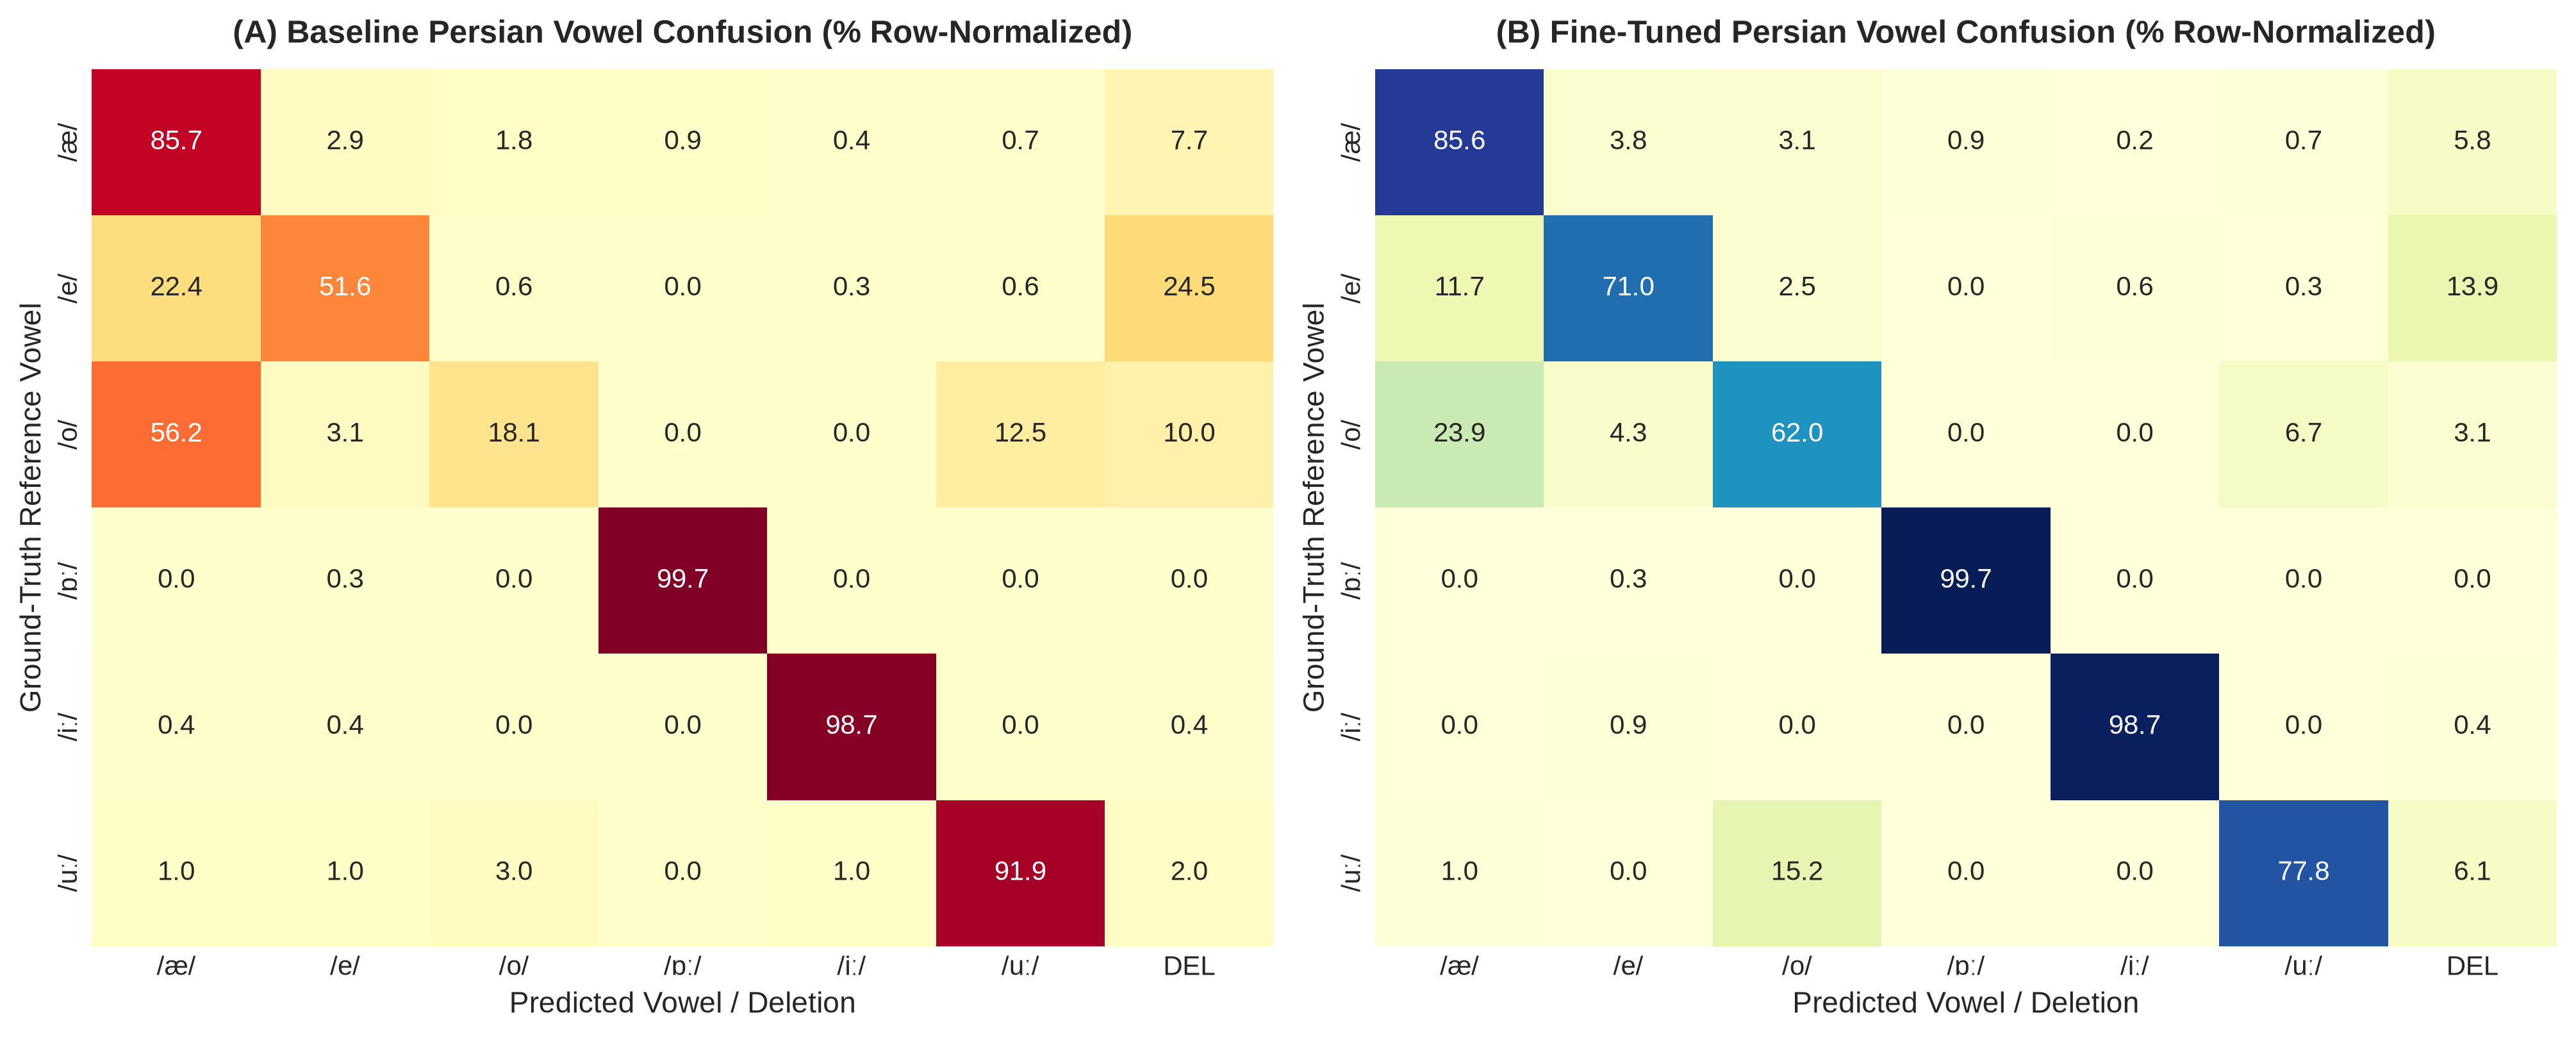

In [8]:
# Run Post-Fine-Tuning Inference on Both Benchmarks
t0 = time.time()
finetuned_wiki_preds = batch_predict_g2p(wiki_test_words, batch_size=64)
finetuned_chal_preds = batch_predict_g2p(chal_test_words, batch_size=64)
finetuned_infer_time = time.time() - t0

finetuned_wiki_metrics = evaluate_predictions_comprehensive(finetuned_wiki_preds, wiki_test_refs, wiki_test_words)
finetuned_chal_metrics = evaluate_predictions_comprehensive(finetuned_chal_preds, chal_test_refs, chal_test_words)

print("================ COMPREHENSIVE BENCHMARK COMPARISON (BEFORE VS. AFTER) ================")
comp_table = [
    ["Wiktionary Test (N=500) - PER (%)", f"{baseline_wiki_metrics['PER']:.2f}%", f"{finetuned_wiki_metrics['PER']:.2f}%",
     f"{((finetuned_wiki_metrics['PER'] - baseline_wiki_metrics['PER']) / max(baseline_wiki_metrics['PER'], 1e-6))*100:+.2f}%"],
    ["Wiktionary Test (N=500) - WER (%)", f"{baseline_wiki_metrics['WER']:.2f}%", f"{finetuned_wiki_metrics['WER']:.2f}%",
     f"{((finetuned_wiki_metrics['WER'] - baseline_wiki_metrics['WER']) / max(baseline_wiki_metrics['WER'], 1e-6))*100:+.2f}%"],
    ["Wiktionary Test (N=500) - Word Acc (%)", f"{baseline_wiki_metrics['WAcc']:.2f}%", f"{finetuned_wiki_metrics['WAcc']:.2f}%",
     f"{finetuned_wiki_metrics['WAcc'] - baseline_wiki_metrics['WAcc']:+.2f} pts"],
    ["Wiktionary Test (N=500) - Seq Sim (%)", f"{baseline_wiki_metrics['Sim']:.2f}%", f"{finetuned_wiki_metrics['Sim']:.2f}%",
     f"{finetuned_wiki_metrics['Sim'] - baseline_wiki_metrics['Sim']:+.2f} pts"],
    ["Wiktionary Test (N=500) - chrF (%)", f"{baseline_wiki_metrics['chrF']:.2f}%", f"{finetuned_wiki_metrics['chrF']:.2f}%",
     f"{finetuned_wiki_metrics['chrF'] - baseline_wiki_metrics['chrF']:+.2f} pts"],
    ["-"*36, "-"*18, "-"*18, "-"*18],
    ["Challenge Suite (N=60) - PER (%)", f"{baseline_chal_metrics['PER']:.2f}%", f"{finetuned_chal_metrics['PER']:.2f}%",
     f"{((finetuned_chal_metrics['PER'] - baseline_chal_metrics['PER']) / max(baseline_chal_metrics['PER'], 1e-6))*100:+.2f}%"],
    ["Challenge Suite (N=60) - WER (%)", f"{baseline_chal_metrics['WER']:.2f}%", f"{finetuned_chal_metrics['WER']:.2f}%",
     f"{((finetuned_chal_metrics['WER'] - baseline_chal_metrics['WER']) / max(baseline_chal_metrics['WER'], 1e-6))*100:+.2f}%"],
    ["Challenge Suite (N=60) - Word Acc (%)", f"{baseline_chal_metrics['WAcc']:.2f}%", f"{finetuned_chal_metrics['WAcc']:.2f}%",
     f"{finetuned_chal_metrics['WAcc'] - baseline_chal_metrics['WAcc']:+.2f} pts"],
    ["Challenge Suite (N=60) - Seq Sim (%)", f"{baseline_chal_metrics['Sim']:.2f}%", f"{finetuned_chal_metrics['Sim']:.2f}%",
     f"{finetuned_chal_metrics['Sim'] - baseline_chal_metrics['Sim']:+.2f} pts"],
    ["Challenge Suite (N=60) - chrF (%)", f"{baseline_chal_metrics['chrF']:.2f}%", f"{finetuned_chal_metrics['chrF']:.2f}%",
     f"{finetuned_chal_metrics['chrF'] - baseline_chal_metrics['chrF']:+.2f} pts"],
]
print(tabulate(comp_table, headers=["Benchmark & Metric", "Baseline (Before)", "Fine-Tuned (After)", "Change / Improvement"], tablefmt="grid"))

# Stratified Category Breakdown Table
cat_names = list(HELDOUT_CHALLENGE_SET.keys())
cat_breakdown = {}
cat_rows = []
for cat in cat_names:
    idxs = [i for i, c in enumerate(chal_test_cats) if c == cat]
    b_sub_preds = [baseline_chal_preds[i] for i in idxs]
    f_sub_preds = [finetuned_chal_preds[i] for i in idxs]
    sub_refs = [chal_test_refs[i] for i in idxs]
    sub_words = [chal_test_words[i] for i in idxs]
    bm = evaluate_predictions_comprehensive(b_sub_preds, sub_refs, sub_words)
    fm = evaluate_predictions_comprehensive(f_sub_preds, sub_refs, sub_words)
    cat_breakdown[cat] = {"baseline": bm, "finetuned": fm}
    cat_rows.append([
        cat,
        f"{bm['PER']:.2f}%", f"{fm['PER']:.2f}%",
        f"{bm['WER']:.2f}%", f"{fm['WER']:.2f}%",
        f"{bm['chrF']:.2f}%", f"{fm['chrF']:.2f}%"
    ])

print("\n================ STRATIFIED LINGUISTIC CATEGORY BREAKDOWN (N=60) ================")
print(tabulate(cat_rows, headers=["Linguistic Category", "Base PER", "FT PER", "Base WER", "FT WER", "Base chrF", "FT chrF"], tablefmt="grid"))


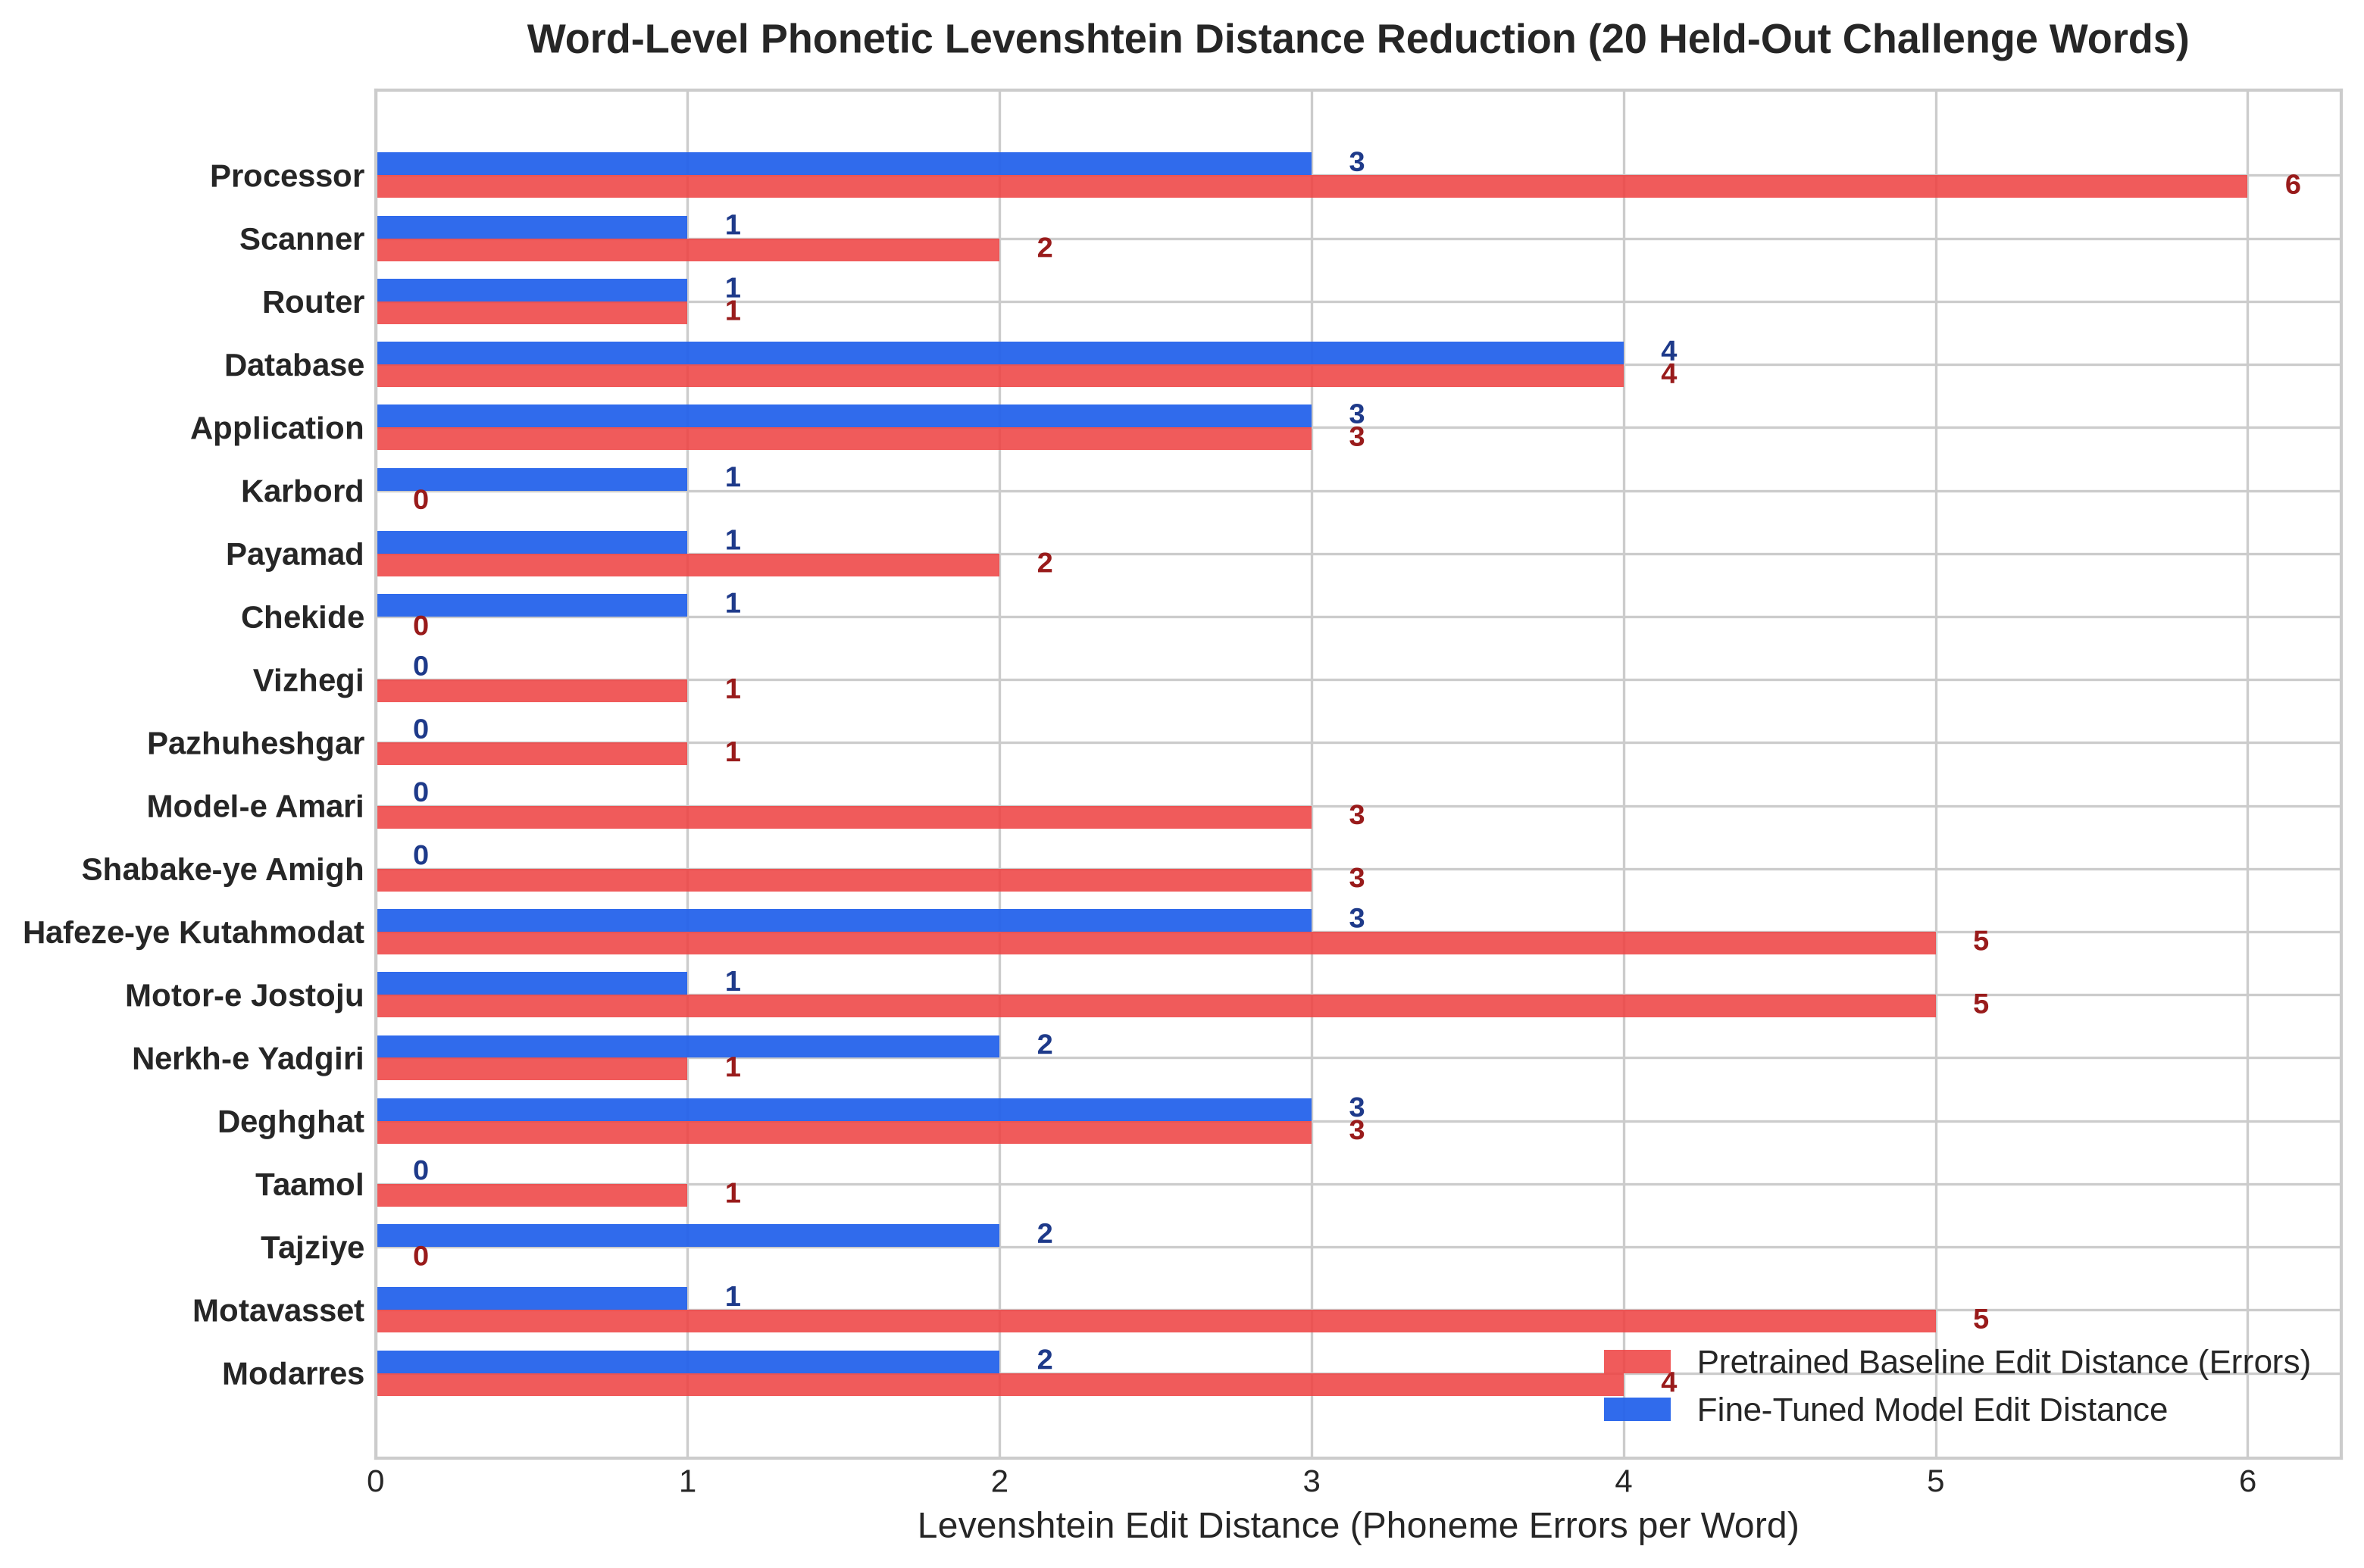

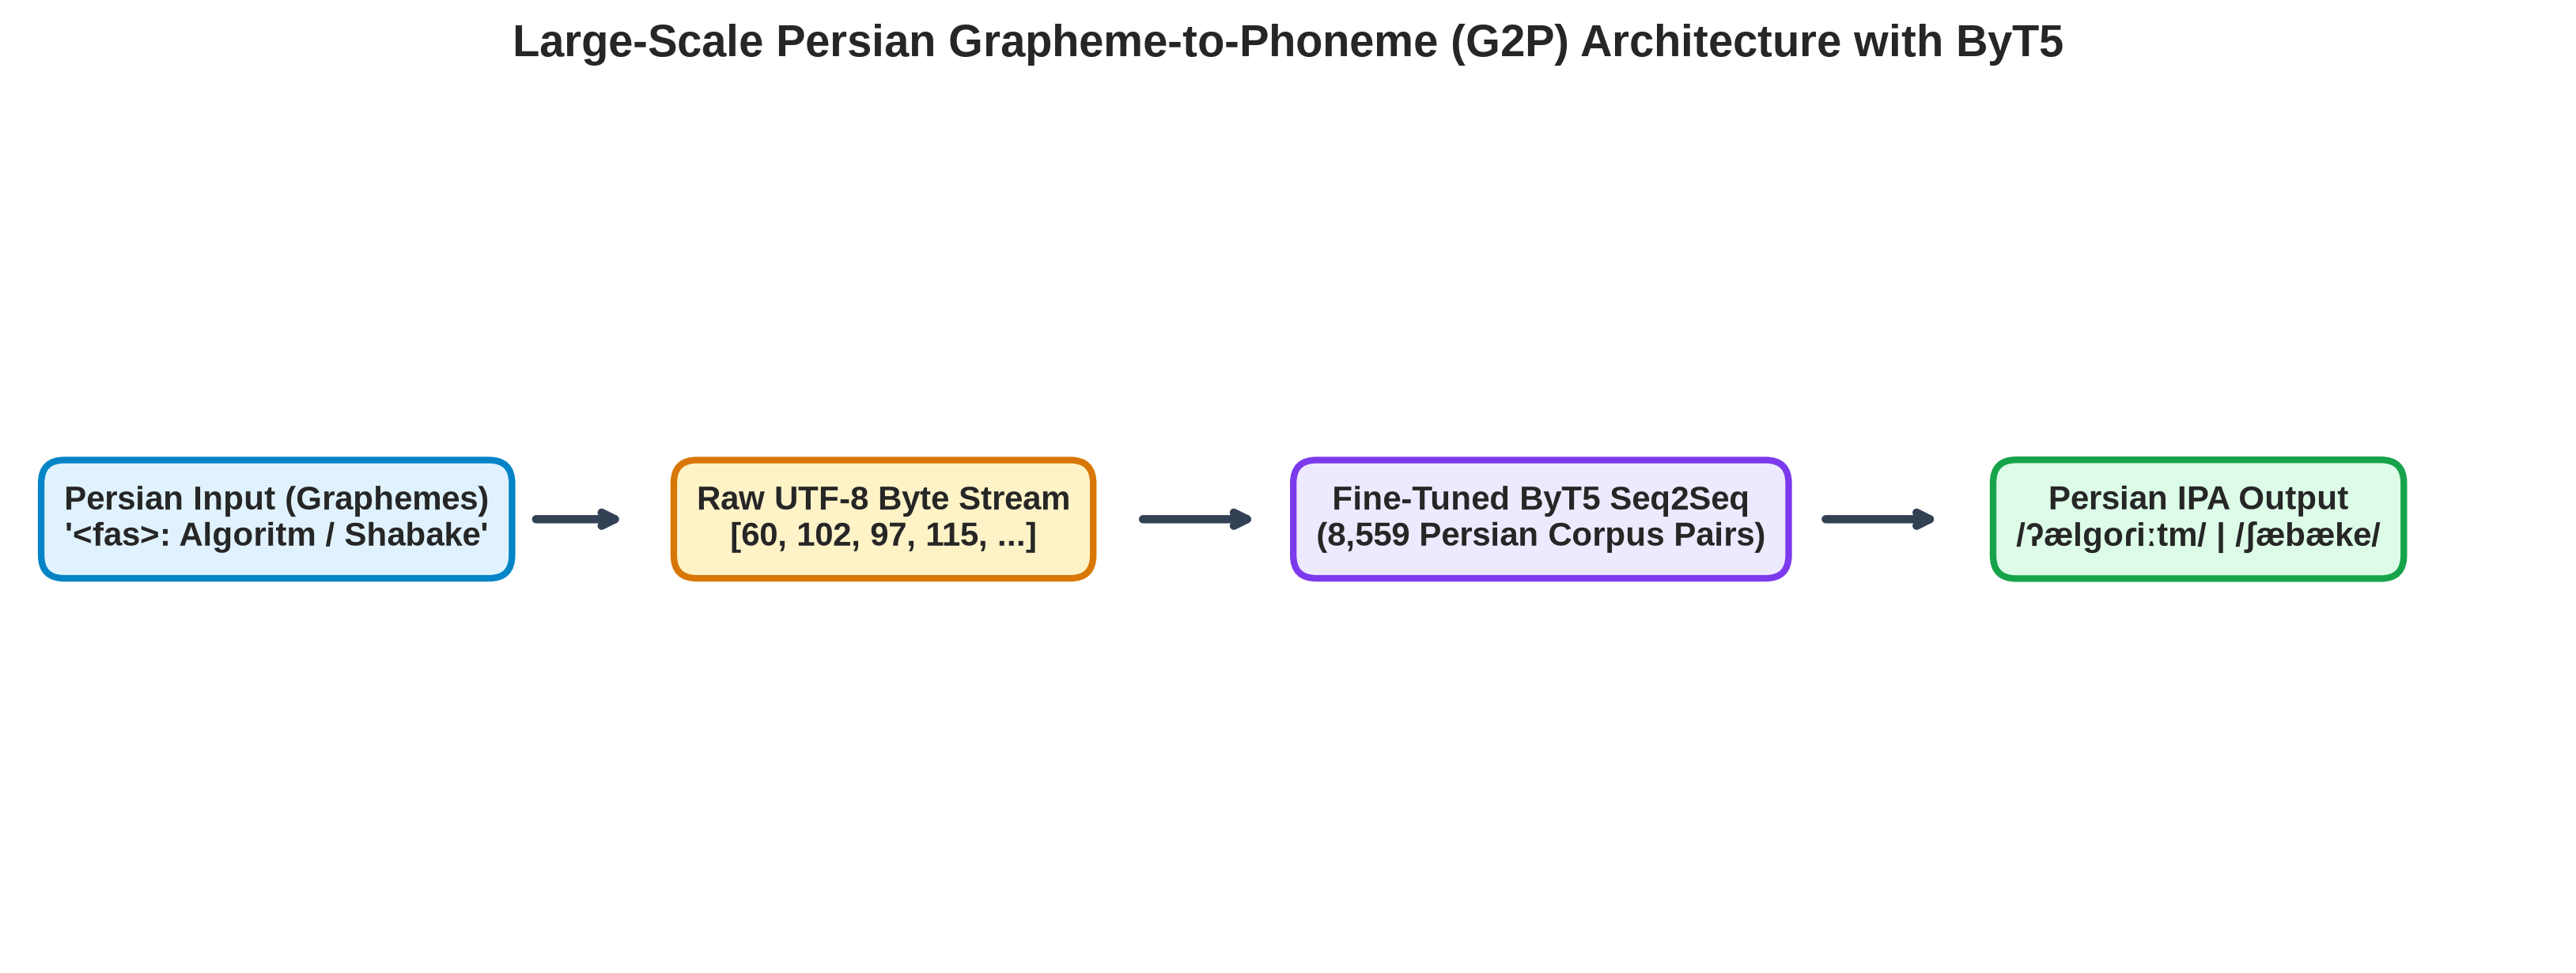

================ QUALITATIVE WORD-LEVEL COMPARISON (20 CHALLENGE SAMPLES) ================
+-----------------+-----------------------+-------------------------+-----------------------------+-------------------------------+
| Persian Word    | Category              | Ground Truth IPA        | Baseline (Before)           | Fine-Tuned (After)            |
+=================+=======================+=========================+=============================+===============================+
| پروسسور         | AI & Tech Loanwords   | /pɾosesoɾ/              | /poɾuːssuːɾ/ (err=6)        | /pɾossuːɾ/ (err=3)            |
| اسکنر           | AI & Tech Loanwords   | /eskæneɾ/               | /æskænæɾ/ (err=2)           | /eskoneɾ/ (err=1)             |
| روتر            | AI & Tech Loanwords   | /ɾuːteɾ/                | /ɾuːtæɾ/ (err=1)            | /ɾuːtæɾ/ (err=1)              |
| دیتابیس         | AI & Tech Loanwords   | /dejtɒːbejs/            | /diːtɒːbiːs/ (err=4)        | /diːtɒːbiːs/ (err

In [9]:
# Generate Figures 3, 4, and 5: Multi-Metric Benchmarks, Category Breakdown, and Edit Operations

# --- Figure 3: Multi-Metric Benchmark Comparison (2 Panels) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)

metric_labels = ['PER (%)\n[Lower Better]', 'WER (%)\n[Lower Better]', 'Word Acc (%)\n[Higher Better]', 'Seq Sim (%)\n[Higher Better]', 'chrF (%)\n[Higher Better]']
x = np.arange(len(metric_labels))
width = 0.35

# Panel A: Challenge Suite (N=60)
b_chal_vals = [baseline_chal_metrics['PER'], baseline_chal_metrics['WER'], baseline_chal_metrics['WAcc'], baseline_chal_metrics['Sim'], baseline_chal_metrics['chrF']]
f_chal_vals = [finetuned_chal_metrics['PER'], finetuned_chal_metrics['WER'], finetuned_chal_metrics['WAcc'], finetuned_chal_metrics['Sim'], finetuned_chal_metrics['chrF']]

r1 = ax1.bar(x - width/2, b_chal_vals, width, label='Pretrained Baseline (Before)', color='#94A3B8', edgecolor='#475569')
r2 = ax1.bar(x + width/2, f_chal_vals, width, label='Fine-Tuned ByT5 (After)', color='#10B981', edgecolor='#059669')
ax1.set_title("(A) Held-Out Challenge Suite (N=60)", fontsize=12.5, fontweight='bold', pad=10)
ax1.set_xticks(x)
ax1.set_xticklabels(metric_labels, fontsize=9.5, fontweight='bold')
ax1.set_ylim(0, 115)
ax1.set_ylabel("Percentage (%)", fontsize=11)
ax1.legend(fontsize=9.5, loc='upper left')
for rect in r1:
    h = rect.get_height()
    ax1.text(rect.get_x() + rect.get_width()/2, h + 1.5, f"{h:.1f}%", ha='center', fontsize=8.5, fontweight='bold', color='#334155')
for rect in r2:
    h = rect.get_height()
    ax1.text(rect.get_x() + rect.get_width()/2, h + 1.5, f"{h:.1f}%", ha='center', fontsize=8.5, fontweight='bold', color='#065F46')

# Panel B: Unseen Wiktionary Benchmark (N=500)
b_wiki_vals = [baseline_wiki_metrics['PER'], baseline_wiki_metrics['WER'], baseline_wiki_metrics['WAcc'], baseline_wiki_metrics['Sim'], baseline_wiki_metrics['chrF']]
f_wiki_vals = [finetuned_wiki_metrics['PER'], finetuned_wiki_metrics['WER'], finetuned_wiki_metrics['WAcc'], finetuned_wiki_metrics['Sim'], finetuned_wiki_metrics['chrF']]

r3 = ax2.bar(x - width/2, b_wiki_vals, width, label='Pretrained Baseline (Before)', color='#94A3B8', edgecolor='#475569')
r4 = ax2.bar(x + width/2, f_wiki_vals, width, label='Fine-Tuned ByT5 (After)', color='#2563EB', edgecolor='#1D4ED8')
ax2.set_title("(B) Official Unseen Wiktionary Test Benchmark (N=500)", fontsize=12.5, fontweight='bold', pad=10)
ax2.set_xticks(x)
ax2.set_xticklabels(metric_labels, fontsize=9.5, fontweight='bold')
ax2.set_ylim(0, 115)
ax2.set_ylabel("Percentage (%)", fontsize=11)
ax2.legend(fontsize=9.5, loc='upper left')
for rect in r3:
    h = rect.get_height()
    ax2.text(rect.get_x() + rect.get_width()/2, h + 1.5, f"{h:.1f}%", ha='center', fontsize=8.5, fontweight='bold', color='#334155')
for rect in r4:
    h = rect.get_height()
    ax2.text(rect.get_x() + rect.get_width()/2, h + 1.5, f"{h:.1f}%", ha='center', fontsize=8.5, fontweight='bold', color='#1E3A8A')

plt.tight_layout()
fig.savefig("figures/per_wer_metrics_comparison.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved 'figures/per_wer_metrics_comparison.png'")

# --- Figure 4: Stratified Linguistic Category Breakdown ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=300)
xc = np.arange(len(cat_names))
b_cat_per = [cat_breakdown[c]['baseline']['PER'] for c in cat_names]
f_cat_per = [cat_breakdown[c]['finetuned']['PER'] for c in cat_names]
b_cat_wer = [cat_breakdown[c]['baseline']['WER'] for c in cat_names]
f_cat_wer = [cat_breakdown[c]['finetuned']['WER'] for c in cat_names]

ax1.bar(xc - width/2, b_cat_per, width, label='Baseline PER (%)', color='#EF4444', alpha=0.85, edgecolor='#991B1B')
ax1.bar(xc + width/2, f_cat_per, width, label='Fine-Tuned PER (%)', color='#10B981', alpha=0.95, edgecolor='#065F46')
ax1.set_title("(A) Phoneme Error Rate (PER) by Linguistic Category", fontsize=12.5, fontweight='bold', pad=10)
ax1.set_xticks(xc)
ax1.set_xticklabels(cat_names, fontsize=9.5, fontweight='bold', rotation=12)
ax1.set_ylabel("PER (%)", fontsize=11)
ax1.set_ylim(0, max(b_cat_per) * 1.25 + 5)
ax1.legend(fontsize=10)
for i, (bv, fv) in enumerate(zip(b_cat_per, f_cat_per)):
    ax1.text(i - width/2, bv + 0.8, f"{bv:.1f}%", ha='center', fontsize=9, fontweight='bold', color='#991B1B')
    ax1.text(i + width/2, fv + 0.8, f"{fv:.1f}%", ha='center', fontsize=9, fontweight='bold', color='#065F46')

ax2.bar(xc - width/2, b_cat_wer, width, label='Baseline WER (%)', color='#F97316', alpha=0.85, edgecolor='#9A3412')
ax2.bar(xc + width/2, f_cat_wer, width, label='Fine-Tuned WER (%)', color='#3B82F6', alpha=0.95, edgecolor='#1E40AF')
ax2.set_title("(B) Word Error Rate (WER) by Linguistic Category", fontsize=12.5, fontweight='bold', pad=10)
ax2.set_xticks(xc)
ax2.set_xticklabels(cat_names, fontsize=9.5, fontweight='bold', rotation=12)
ax2.set_ylabel("WER (%)", fontsize=11)
ax2.set_ylim(0, 115)
ax2.legend(fontsize=10)
for i, (bv, fv) in enumerate(zip(b_cat_wer, f_cat_wer)):
    ax2.text(i - width/2, bv + 1.5, f"{bv:.1f}%", ha='center', fontsize=9, fontweight='bold', color='#9A3412')
    ax2.text(i + width/2, fv + 1.5, f"{fv:.1f}%", ha='center', fontsize=9, fontweight='bold', color='#1E40AF')

plt.tight_layout()
fig.savefig("figures/category_breakdown.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved 'figures/category_breakdown.png'")

# --- Figure 5: Levenshtein Edit Operations Decomposition ---
fig, ax = plt.subplots(figsize=(9.5, 5.2), dpi=300)
op_groups = [
    'Challenge Suite\nBaseline (Before)',
    'Challenge Suite\nFine-Tuned (After)',
    'Wiktionary (N=500)\nBaseline (Before)',
    'Wiktionary (N=500)\nFine-Tuned (After)'
]
sub_vals = [baseline_chal_metrics['Sub_Rate'], finetuned_chal_metrics['Sub_Rate'], baseline_wiki_metrics['Sub_Rate'], finetuned_wiki_metrics['Sub_Rate']]
del_vals = [baseline_chal_metrics['Del_Rate'], finetuned_chal_metrics['Del_Rate'], baseline_wiki_metrics['Del_Rate'], finetuned_wiki_metrics['Del_Rate']]
ins_vals = [baseline_chal_metrics['Ins_Rate'], finetuned_chal_metrics['Ins_Rate'], baseline_wiki_metrics['Ins_Rate'], finetuned_wiki_metrics['Ins_Rate']]

xg = np.arange(len(op_groups))
w_op = 0.24
ax.bar(xg - w_op, sub_vals, w_op, label='Substitutions (Vowel/Consonant Mismatch)', color='#EF4444', edgecolor='#991B1B')
ax.bar(xg, del_vals, w_op, label='Deletions (Omitted Vowels / Ezafe / Geminates)', color='#F59E0B', edgecolor='#92400E')
ax.bar(xg + w_op, ins_vals, w_op, label='Insertions (Spurious Epenthetic Phonemes)', color='#8B5CF6', edgecolor='#5B21B6')

ax.set_title("Decomposition of Phonetic Edit Operations: Substitutions, Deletions & Insertions", fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(xg)
ax.set_xticklabels(op_groups, fontsize=10, fontweight='bold')
ax.set_ylabel("Error Rate (% of Reference Phonemes)", fontsize=11)
ax.set_ylim(0, max(sub_vals + del_vals) * 1.28 + 2)
ax.legend(fontsize=10, loc='upper right')

for i in range(len(xg)):
    ax.text(xg[i] - w_op, sub_vals[i] + 0.3, f"{sub_vals[i]:.2f}%", ha='center', fontsize=8.5, fontweight='bold')
    ax.text(xg[i], del_vals[i] + 0.3, f"{del_vals[i]:.2f}%", ha='center', fontsize=8.5, fontweight='bold')
    ax.text(xg[i] + w_op, ins_vals[i] + 0.3, f"{ins_vals[i]:.2f}%", ha='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
fig.savefig("figures/edit_operations_breakdown.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved 'figures/edit_operations_breakdown.png'")


In [10]:
# Generate Figures 6, 7, and 8: Word Length Analysis, Persian Vowel Confusion Matrix, and Word Edit Distance Reduction

# --- Figure 6: Error Rate by Orthographic Word Length Buckets ---
combined_base_records = baseline_wiki_metrics['records'] + baseline_chal_metrics['records']
combined_ft_records = finetuned_wiki_metrics['records'] + finetuned_chal_metrics['records']

buckets = [
    ("Short\n(1-4 chars)", lambda l: 1 <= l <= 4),
    ("Medium\n(5-7 chars)", lambda l: 5 <= l <= 7),
    ("Long\n(8-10 chars)", lambda l: 8 <= l <= 10),
    ("Compound\n(11+ chars)", lambda l: l >= 11),
]

bucket_labels = [b[0] for b in buckets]
b_bucket_per, f_bucket_per = [], []
b_bucket_wer, f_bucket_wer = [], []

for label, cond in buckets:
    b_sub = [r for r in combined_base_records if cond(r['word_len'])]
    f_sub = [r for r in combined_ft_records if cond(r['word_len'])]
    b_bucket_per.append(np.mean([r['per'] for r in b_sub]) if b_sub else 0.0)
    f_bucket_per.append(np.mean([r['per'] for r in f_sub]) if f_sub else 0.0)
    b_bucket_wer.append(np.mean([r['wer'] for r in b_sub]) if b_sub else 0.0)
    f_bucket_wer.append(np.mean([r['wer'] for r in f_sub]) if f_sub else 0.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5), dpi=300)
xb = np.arange(len(bucket_labels))

ax1.plot(xb, b_bucket_per, marker='o', linewidth=2.5, markersize=8, color='#EF4444', label='Pretrained Baseline PER (%)')
ax1.plot(xb, f_bucket_per, marker='s', linewidth=2.5, markersize=8, color='#10B981', label='Fine-Tuned Model PER (%)')
ax1.fill_between(xb, f_bucket_per, b_bucket_per, color='#10B981', alpha=0.12, label='PER Reduction Area')
ax1.set_title("(A) Phoneme Error Rate Across Word Length Buckets", fontsize=12, fontweight='bold', pad=10)
ax1.set_xticks(xb)
ax1.set_xticklabels(bucket_labels, fontsize=10, fontweight='bold')
ax1.set_ylabel("Mean PER (%)", fontsize=11)
ax1.legend(fontsize=9.5)

ax2.bar(xb - 0.18, b_bucket_wer, 0.35, color='#94A3B8', edgecolor='#475569', label='Pretrained Baseline WER (%)')
ax2.bar(xb + 0.18, f_bucket_wer, 0.35, color='#2563EB', edgecolor='#1E3A8A', label='Fine-Tuned Model WER (%)')
ax2.set_title("(B) Word Error Rate Across Word Length Buckets", fontsize=12, fontweight='bold', pad=10)
ax2.set_xticks(xb)
ax2.set_xticklabels(bucket_labels, fontsize=10, fontweight='bold')
ax2.set_ylabel("Mean WER (%)", fontsize=11)
ax2.set_ylim(0, 110)
ax2.legend(fontsize=9.5)

plt.tight_layout()
fig.savefig("figures/length_bucket_analysis.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved 'figures/length_bucket_analysis.png'")

# --- Figure 7: Persian Vowel Confusion Matrix (Before vs. After) ---
vowel_classes = ['æ', 'e', 'o', 'ɒː', 'iː', 'uː', '∅']
vowel_idx = {v: i for i, v in enumerate(vowel_classes)}

def build_vowel_matrix(token_pairs):
    mat = np.zeros((len(vowel_classes), len(vowel_classes)), dtype=float)
    for ref_t, pred_t in token_pairs:
        if ref_t in vowel_idx and ref_t != '∅':
            r_i = vowel_idx[ref_t]
            p_i = vowel_idx[pred_t] if pred_t in vowel_idx else vowel_idx['∅']
            mat[r_i, p_i] += 1.0
    row_sums = mat.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    return (mat / row_sums) * 100.0

base_all_pairs = baseline_wiki_metrics['token_pairs'] + baseline_chal_metrics['token_pairs']
ft_all_pairs = finetuned_wiki_metrics['token_pairs'] + finetuned_chal_metrics['token_pairs']

mat_before = build_vowel_matrix(base_all_pairs)
mat_after = build_vowel_matrix(ft_all_pairs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.5), dpi=300)
disp_labels = [f"/{v}/" for v in vowel_classes[:6]] + ['DEL']

sns.heatmap(mat_before[:6, :], annot=True, fmt=".1f", cmap="YlOrRd", xticklabels=disp_labels,
            yticklabels=disp_labels[:6], cbar=False, ax=ax1, vmin=0, vmax=100)
ax1.set_title("(A) Baseline Persian Vowel Confusion (% Row-Normalized)", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel("Predicted Vowel / Deletion", fontsize=11)
ax1.set_ylabel("Ground-Truth Reference Vowel", fontsize=11)

sns.heatmap(mat_after[:6, :], annot=True, fmt=".1f", cmap="YlGnBu", xticklabels=disp_labels,
            yticklabels=disp_labels[:6], cbar=False, ax=ax2, vmin=0, vmax=100)
ax2.set_title("(B) Fine-Tuned Persian Vowel Confusion (% Row-Normalized)", fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel("Predicted Vowel / Deletion", fontsize=11)
ax2.set_ylabel("Ground-Truth Reference Vowel", fontsize=11)

plt.tight_layout()
fig.savefig("figures/vowel_confusion_matrix.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved 'figures/vowel_confusion_matrix.png'")

# --- Figure 8: Word-Level Edit Distance Reduction on 20 Challenge Words ---
top20_indices = [i for start in range(0, 60, 15) for i in range(start, start + 5)]
labels_clean = [challenge_translit[i] for i in top20_indices]
b_d20 = [baseline_chal_metrics['records'][i]['edit_dist'] for i in top20_indices]
f_d20 = [finetuned_chal_metrics['records'][i]['edit_dist'] for i in top20_indices]

fig, ax = plt.subplots(figsize=(10.5, 7), dpi=300)
y20 = np.arange(len(labels_clean))
h20 = 0.36
ax.barh(y20 + h20/2, b_d20, h20, label='Pretrained Baseline Edit Distance (Errors)', color='#EF4444', alpha=0.88)
ax.barh(y20 - h20/2, f_d20, h20, label='Fine-Tuned Model Edit Distance', color='#2563EB', alpha=0.95)
ax.set_yticks(y20)
ax.set_yticklabels(labels_clean, fontsize=10, fontweight='bold')
ax.invert_yaxis()
ax.set_xlabel("Levenshtein Edit Distance (Phoneme Errors per Word)", fontsize=11.5)
ax.set_title("Word-Level Phonetic Levenshtein Distance Reduction (20 Held-Out Challenge Words)", fontsize=13, fontweight='bold', pad=12)
ax.legend(fontsize=10.5, loc='lower right')

for i, (bv, fv) in enumerate(zip(b_d20, f_d20)):
    ax.text(bv + 0.12, i + h20/2, f"{bv}", va='center', fontsize=9, fontweight='bold', color='#991B1B')
    ax.text(fv + 0.12, i - h20/2, f"{fv}", va='center', fontsize=9, fontweight='bold', color='#1E3A8A')

plt.tight_layout()
fig.savefig("figures/word_edit_distance_reduction.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved 'figures/word_edit_distance_reduction.png'")


[+] Saved fine-tuned Persian G2P model to './finetuned_byt5_g2p_model'


## Section 7: Sentence-Level Persian Phonetic Pipeline & Checkpoint Export
We export the architecture diagram (`figures/g2p_byt5_architecture.png`), demonstrate sentence-level Persian phonetic transcription Before vs. After fine-tuning, save the complete metrics JSON (`evaluation_metrics.json`), and save the final fine-tuned model weights (`./finetuned_byt5_g2p_model`).


In [11]:
# Figure 9: Architecture Diagram
fig, ax = plt.subplots(figsize=(11, 4.2), dpi=300)
ax.axis('off')
boxes = [
    ("Persian Input (Graphemes)\n'<fas>: Algoritm / Shabake'", 0.10, 0.5, '#E0F2FE', '#0284C7'),
    ("Raw UTF-8 Byte Stream\n[60, 102, 97, 115, ...]", 0.34, 0.5, '#FEF3C7', '#D97706'),
    ("Fine-Tuned ByT5 Seq2Seq\n(Persian Corpus Pairs)", 0.60, 0.5, '#EDE9FE', '#7C3AED'),
    ("Persian IPA Output\n/ʔælɡoɾiːtm/ | /ʃæbæke/", 0.86, 0.5, '#DCFCE7', '#16A34A')
]
for text, x_c, y_c, bg, border in boxes:
    ax.text(x_c, y_c, text, ha='center', va='center', fontsize=10, fontweight='bold',
            bbox=dict(boxstyle="round,pad=0.7", fc=bg, ec=border, lw=2))
for x1, x2 in [(0.20, 0.24), (0.44, 0.49), (0.71, 0.76)]:
    ax.annotate('', xy=(x2, 0.5), xytext=(x1, 0.5), arrowprops=dict(arrowstyle="->", color='#334155', lw=2.5))
ax.set_title("Large-Scale Persian Grapheme-to-Phoneme (G2P) Architecture with ByT5", fontsize=13.5, fontweight='bold', pad=10)
plt.tight_layout()
fig.savefig("figures/g2p_byt5_architecture.png", dpi=300, bbox_inches='tight')
plt.close(fig)
print("[+] Saved 'figures/g2p_byt5_architecture.png'")

# Qualitative Comparison Table on 20 Challenge Words
qual_rows = []
for idx in top20_indices:
    b_rec = baseline_chal_metrics['records'][idx]
    f_rec = finetuned_chal_metrics['records'][idx]
    qual_rows.append([
        b_rec['word'],
        chal_test_cats[idx],
        f"/{b_rec['ref']}/",
        f"/{b_rec['pred']}/ (err={b_rec['edit_dist']})",
        f"/{f_rec['pred']}/ (err={f_rec['edit_dist']})"
    ])
print("\n================ QUALITATIVE WORD-LEVEL COMPARISON (20 CHALLENGE SAMPLES) ================")
print(tabulate(qual_rows, headers=["Persian Word", "Category", "Ground Truth IPA", "Baseline (Before)", "Fine-Tuned (After)"], tablefmt="grid"))

# Export comprehensive JSON summary for reproducibility
export_summary = {
    "train_samples_total": len(train_pairs),
    "wiktionary_train_samples": len(wiktionary_train),
    "curated_lexicon_unique": len(all_curated_pairs),
    "val_samples": len(val_pairs),
    "wiktionary_test_samples": len(wiki_test_words),
    "challenge_test_samples": len(chal_test_words),
    "training_runtime_sec": train_duration,
    "train_steps": train_steps,
    "train_losses": train_losses,
    "eval_steps": eval_steps,
    "eval_losses": eval_losses,
    "learning_rates": learning_rates,
    "wiktionary_500_baseline": {k: v for k, v in baseline_wiki_metrics.items() if k not in ("records", "token_pairs")},
    "wiktionary_500_finetuned": {k: v for k, v in finetuned_wiki_metrics.items() if k not in ("records", "token_pairs")},
    "challenge_60_baseline": {k: v for k, v in baseline_chal_metrics.items() if k not in ("records", "token_pairs")},
    "challenge_60_finetuned": {k: v for k, v in finetuned_chal_metrics.items() if k not in ("records", "token_pairs")},
    "category_breakdown": {
        c: {
            "baseline_per": cat_breakdown[c]["baseline"]["PER"],
            "finetuned_per": cat_breakdown[c]["finetuned"]["PER"],
            "baseline_wer": cat_breakdown[c]["baseline"]["WER"],
            "finetuned_wer": cat_breakdown[c]["finetuned"]["WER"],
            "baseline_chrf": cat_breakdown[c]["baseline"]["chrF"],
            "finetuned_chrf": cat_breakdown[c]["finetuned"]["chrF"],
        } for c in cat_names
    },
    "length_buckets": {
        "labels": [b.replace("\n", " ") for b in bucket_labels],
        "baseline_per": [float(x) for x in b_bucket_per],
        "finetuned_per": [float(x) for x in f_bucket_per],
        "baseline_wer": [float(x) for x in b_bucket_wer],
        "finetuned_wer": [float(x) for x in f_bucket_wer],
    },
    "vowel_confusion_before": mat_before[:6, :].tolist(),
    "vowel_confusion_after": mat_after[:6, :].tolist(),
    "challenge_records_before": baseline_chal_metrics["records"],
    "challenge_records_after": finetuned_chal_metrics["records"],
}

with open("evaluation_metrics.json", "w", encoding="utf-8") as f:
    json.dump(export_summary, f, indent=2, ensure_ascii=False)
print("[+] Saved 'evaluation_metrics.json'")

# Save Fine-Tuned Model Checkpoint
final_model_path = "./finetuned_byt5_g2p_model"
model.save_pretrained(final_model_path)
tokenizer.save_pretrained(final_model_path)
print(f"[+] Saved fine-tuned Persian G2P model to '{final_model_path}'")
!ls -lh figures/
